# E6 — Optimisation Pass, Final Pipeline and Consolidated Benchmark

| Section | Question |
|---|---|
| 6.1 | How does latency scale with CPU threads? |
| 6.2 | Can YOLOv8n-seg masks replace MobileSAM (−39 MB, −2 s)? |
| 6.3 | Does exporting YOLOv8n-seg to ONNX Runtime make it faster? |
| 6.4 | Diffusion knobs: LCM steps × resolution × VAE × guidance |
| 6.5 | **Final pipeline** `edit_image(image, instruction)` |
| 6.6 | Final benchmark: per-stage latency and **peak RAM** |
| 6.7 | Runtime dependency footprint |
| 6.8 | **Consolidated E0 → E6 summary** and the quality / size / latency trade-off plot |
| 6.9 | (optional) int8 dynamic quantisation of the UNet |

**Final pipeline design:**

```
instruction ─► LLM parser (regex fallback)
            ─► router: COCO class?  yes ─► YOLOv8n-seg (box + mask in one pass)
                                    no  ─► YOLO-World (open vocab) ─► MobileSAM
            ─► MI-GAN removal (ONNX)
            ─► replace?  diffusion ─► SD-1.5-inpaint + LCM-LoRA (4 steps) + TAESD
                         composite ─► cutout from the asset library (fast mode)
```

⏱️ Runtime on 2-vCPU Colab is about 30–40 min.

> If Colab asks you to restart after the install cell, restart it, then run from the imports cell.

In [33]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [34]:
!pip install -q -U ultralytics onnxruntime
!pip install -q git+https://github.com/ChaoningZhang/MobileSAM.git
!pip install -q onnx onnxslim

# CLIP text encoder used by YOLO-World's set_classes()
!pip install -q git+https://github.com/ultralytics/CLIP.git

# llama.cpp runtime for the 4-bit LLM. Prebuilt CPU wheel only -> fails fast instead of a ~15 min source build.
# If it fails, the notebook automatically uses the transformers backend (bigger + slower, but works).
!pip install -q --only-binary=llama-cpp-python llama-cpp-python --extra-index-url https://abetlen.github.io/llama-cpp-python/whl/cpu || echo "No prebuilt llama-cpp-python wheel -> transformers backend will be used"

# Same pinned set that worked in E3 (diffusers 0.40 needs huggingface-hub >= 1.23; optimum downgrades it)
!pip uninstall -y -q optimum optimum-onnx
!pip install -q -U "diffusers==0.40.0" "transformers>=4.41.2,<6" "accelerate>=1.1.0" "safetensors>=0.8.0" "peft>=0.20.0" "huggingface-hub>=1.23.0,<2.0"

  Preparing metadata (setup.py) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [35]:
import os
import re
import gc
import sys
import json
import time
import glob
import platform
import subprocess
import threading
import warnings
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import torch
from PIL import Image

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import ultralytics
from ultralytics import YOLO
from mobile_sam import sam_model_registry, SamPredictor
import onnxruntime as ort

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("ONNX Runtime:", ort.__version__)

Python: 3.13.15
PyTorch: 2.11.0+cpu
Ultralytics: 8.4.166
ONNX Runtime: 1.30.0


In [36]:
BASE_DIR = "/content/drive/MyDrive/inter_IIT/Task_2/"
IMAGE_DIR = BASE_DIR
ASSET_DIR = os.path.join(BASE_DIR, "assets")
MODEL_DIR = os.path.join(BASE_DIR, "models")
BENCHMARK_DIR = os.path.join(BASE_DIR, "benchmarks")
RESULTS_DIR = os.path.join(BASE_DIR, "results", "E6")

for d in [MODEL_DIR, BENCHMARK_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

DEVICE = "cpu"
# E0-E3 used cpu_count() // 2 (= 1 thread on 2-vCPU Colab). Use every core.
CPU_THREADS = os.cpu_count() or 2
torch.set_num_threads(CPU_THREADS)
cv2.setNumThreads(CPU_THREADS)
SEED = 42


def cpu_model_name():
    try:
        with open("/proc/cpuinfo") as f:
            for line in f:
                if line.startswith("model name"):
                    return line.split(":", 1)[1].strip()
    except OSError:
        pass
    return platform.processor()


SYSTEM_INFO = {
    "cpu": cpu_model_name(),
    "logical_cores": os.cpu_count(),
    "threads_used": CPU_THREADS,
    "ram_gb": round(psutil.virtual_memory().total / 2**30, 2),
    "python": platform.python_version(),
    "torch": torch.__version__,
    "onnxruntime": ort.__version__,
    "opencv": cv2.__version__,
    "ultralytics": ultralytics.__version__,
}
print(json.dumps(SYSTEM_INFO, indent=2))

with open(os.path.join(BENCHMARK_DIR, "e6_system_info.json"), "w") as f:
    json.dump(SYSTEM_INFO, f, indent=2)

{
  "cpu": "Intel(R) Xeon(R) CPU @ 2.20GHz",
  "logical_cores": 2,
  "threads_used": 2,
  "ram_gb": 12.67,
  "python": "3.13.15",
  "torch": "2.11.0+cpu",
  "onnxruntime": "1.30.0",
  "opencv": "4.14.0",
  "ultralytics": "8.4.166"
}


In [37]:
def file_mb(path):
    return os.path.getsize(path) / 2**20


def params_m(module):
    return sum(p.numel() for p in module.parameters()) / 1e6


def fp32_mb(module):
    """In-memory fp32 weight size (params x 4 bytes)."""
    return sum(p.numel() for p in module.parameters()) * 4 / 2**20


def rss_mb():
    return psutil.Process().memory_info().rss / 2**20


def read_image(name):
    path = name if os.path.isabs(name) else os.path.join(IMAGE_DIR, name)
    img = cv2.imread(path)
    if img is None:  # some test images are AVIF files saved as .jpg
        img = cv2.cvtColor(np.array(Image.open(path).convert("RGB")), cv2.COLOR_RGB2BGR)
    return img


def to_rgb(img):
    return img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def slug(text, n=40):
    return re.sub(r"[^a-z0-9]+", "_", text.lower()).strip("_")[:n]


def save_image(img, name):
    path = os.path.join(RESULTS_DIR, name)
    cv2.imwrite(path, img)
    return path


def show_grid(rows, col_titles, row_titles=None, cell=4.0, save_as=None):
    """rows: list of lists of BGR images / masks / None."""
    nr, nc = len(rows), len(col_titles)
    fig, axes = plt.subplots(nr, nc, figsize=(cell * nc, cell * 0.75 * nr), squeeze=False)
    for r, row in enumerate(rows):
        for c in range(nc):
            ax = axes[r][c]
            ax.axis("off")
            img = row[c] if c < len(row) else None
            title = col_titles[c]
            if row_titles and c == 0:
                title = f"{row_titles[r]}\n{title}"
            ax.set_title(title, fontsize=9)
            if img is None:
                ax.text(0.5, 0.5, "N/A", ha="center", va="center", fontsize=14, transform=ax.transAxes)
                continue
            ax.imshow(to_rgb(img), cmap="gray" if img.ndim == 2 else None)
    plt.tight_layout()
    if save_as:
        fig.savefig(os.path.join(RESULTS_DIR, save_as), dpi=110, bbox_inches="tight")
    plt.show()


def time_it(fn, n=3):
    """Median latency (s) after one warm-up call."""
    fn()
    times = []
    for _ in range(n):
        t0 = time.perf_counter()
        fn()
        times.append(time.perf_counter() - t0)
    return float(np.median(times))


LOAD_STATS = []


def log_load(name, rss_before, size_mb=None, params=None):
    added = rss_mb() - rss_before
    LOAD_STATS.append({"component": name, "size_MB": size_mb, "params_M": params, "ram_added_MB": added})
    size_s = "?" if size_mb is None else f"{size_mb:.2f}"
    params_s = "?" if params is None else f"{params:.2f}"
    print(f"{name}: size={size_s} MB | params={params_s} M | +RAM={added:.0f} MB")

In [38]:
class PeakRSS:
    """Samples process RSS in a background thread; reports the peak during the `with` block."""

    def __init__(self, interval=0.01):
        self.interval = interval

    def __enter__(self):
        self.proc = psutil.Process()
        self.start = self.proc.memory_info().rss
        self.peak = self.start
        self._stop = False
        self._thread = threading.Thread(target=self._run, daemon=True)
        self._thread.start()
        return self

    def _run(self):
        while not self._stop:
            self.peak = max(self.peak, self.proc.memory_info().rss)
            time.sleep(self.interval)

    def __exit__(self, *exc):
        self._stop = True
        self._thread.join()
        self.peak = max(self.peak, self.proc.memory_info().rss)

    @property
    def peak_mb(self):
        return self.peak / 2**20

    @property
    def delta_mb(self):
        return (self.peak - self.start) / 2**20

## Models

In [39]:
r0 = rss_mb()
YOLO_MODEL_NAME = "yolov8n.pt"
yolo_model = YOLO(YOLO_MODEL_NAME)
YOLO_SIZE_MB = file_mb(getattr(yolo_model, "ckpt_path", None) or YOLO_MODEL_NAME)
COCO_NAMES = [yolo_model.names[i].lower() for i in range(len(yolo_model.names))]
log_load("YOLOv8n", r0, YOLO_SIZE_MB, params_m(yolo_model.model))

r0 = rss_mb()
MOBILE_SAM_PATH = os.path.join(MODEL_DIR, "mobile_sam.pt")
if not os.path.exists(MOBILE_SAM_PATH):
    subprocess.run(
        ["wget", "-q", "https://github.com/ChaoningZhang/MobileSAM/raw/master/weights/mobile_sam.pt",
         "-O", MOBILE_SAM_PATH],
        check=True,
    )
mobile_sam = sam_model_registry["vit_t"](checkpoint=MOBILE_SAM_PATH)
mobile_sam.to(DEVICE)
mobile_sam.eval()
predictor = SamPredictor(mobile_sam)
MOBILE_SAM_SIZE_MB = file_mb(MOBILE_SAM_PATH)
log_load("MobileSAM", r0, MOBILE_SAM_SIZE_MB, params_m(mobile_sam))

YOLOv8n: size=6.25 MB | params=3.16 M | +RAM=3 MB
MobileSAM: size=38.84 MB | params=10.13 M | +RAM=3 MB


In [40]:
r0 = rss_mb()
SEG_MODEL_NAME = "yolov8n-seg.pt"
seg_model = YOLO(SEG_MODEL_NAME)
SEG_SIZE_MB = file_mb(getattr(seg_model, "ckpt_path", None) or SEG_MODEL_NAME)
log_load("YOLOv8n-seg", r0, SEG_SIZE_MB, params_m(seg_model.model))

YOLOv8n-seg: size=6.74 MB | params=3.41 M | +RAM=0 MB


In [41]:
def make_ort_session(path, threads=None):
    so = ort.SessionOptions()
    so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    so.intra_op_num_threads = threads or CPU_THREADS
    so.inter_op_num_threads = 1
    so.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
    return ort.InferenceSession(path, sess_options=so, providers=["CPUExecutionProvider"])


r0 = rss_mb()
MIGAN_URL = "https://huggingface.co/andraniksargsyan/migan/resolve/main/migan_pipeline_v2.onnx"
MIGAN_PATH = os.path.join(MODEL_DIR, "migan_pipeline_v2.onnx")
if not os.path.exists(MIGAN_PATH):
    subprocess.run(["wget", "-q", MIGAN_URL, "-O", MIGAN_PATH], check=True)

migan_session = make_ort_session(MIGAN_PATH)
MIGAN_INPUTS = [x.name for x in migan_session.get_inputs()]
MIGAN_OUTPUTS = [x.name for x in migan_session.get_outputs()]
MIGAN_SIZE_MB = file_mb(MIGAN_PATH)
log_load("MI-GAN (ONNX)", r0, MIGAN_SIZE_MB)

MI-GAN (ONNX): size=26.78 MB | params=? M | +RAM=-707 MB


In [42]:
# ---------------- text -> detector vocabulary ----------------
ALIASES = {
    "bike": "bicycle", "cycle": "bicycle", "motorbike": "motorcycle", "scooter": "motorcycle",
    "guy": "person", "man": "person", "men": "person", "woman": "person", "women": "person",
    "people": "person", "persons": "person", "kid": "person", "child": "person", "boy": "person",
    "girl": "person", "cyclist": "person", "rider": "person", "pedestrian": "person",
    "lady": "person", "human": "person",
    "puppy": "dog", "doggy": "dog", "kitten": "cat", "kitty": "cat",
    "sedan": "car", "suv": "car", "vehicle": "car", "automobile": "car", "taxi": "car", "jeep": "car",
    "lorry": "truck", "van": "truck",
    "sofa": "couch", "television": "tv", "monitor": "tv", "phone": "cell phone", "mobile": "cell phone",
    "plant": "potted plant", "ball": "sports ball", "table": "dining table", "bag": "handbag",
}

WHICH_OPTIONS = ["best", "left", "right", "top", "bottom", "center", "largest", "smallest", "all"]


def clean_phrase(text):
    text = str(text or "").lower().strip()
    text = re.sub(r"[.?!,;:]+$", "", text)
    text = re.sub(r"\s+(please|pls|thanks|thank you)$", "", text)
    text = re.sub(r"^(the|a|an|that|this|those|these|all the|all)\s+", "", text)
    return text.strip()


def to_coco_class(phrase):
    """Map a free-text object phrase to a YOLOv8 COCO class name, or 'none'."""
    p = clean_phrase(phrase)
    if not p:
        return "none"
    if p in COCO_NAMES:
        return p
    if p in ALIASES:
        return ALIASES[p]
    words = re.findall(r"[a-z]+", p)
    for i, w in enumerate(words):  # first matching noun = head noun ("man walking near the car" -> man)
        if i + 1 < len(words) and f"{w} {words[i + 1]}" in COCO_NAMES:
            return f"{w} {words[i + 1]}"
        for cand in (w, w[:-1] if w.endswith("s") else None):
            if cand in COCO_NAMES:
                return cand
            if cand in ALIASES:
                return ALIASES[cand]
    return "none"


def default_target_prompt(target):
    return f"a photorealistic {target}, natural lighting, realistic shadow, sharp details, matching the scene"


def make_parse(action, obj, target="", which="best", target_prompt="", coco_class=None, parser="regex"):
    obj = clean_phrase(obj)
    target = clean_phrase(target) if action == "replace" else ""
    return {
        "action": action,
        "object": obj,
        "coco_class": coco_class if coco_class in COCO_NAMES else to_coco_class(obj),
        "which": which if which in WHICH_OPTIONS else "best",
        "target": target,
        "target_prompt": (target_prompt or default_target_prompt(target)) if action == "replace" else "",
        "parser": parser,
    }


REMOVE_RE = re.compile(r"(?:remove|delete|erase|eliminate|get rid of|take out|take away)\s+(.+)")
REPLACE_RES = [
    re.compile(r"(?:replace|swap|exchange)\s+(.+?)\s+(?:with|for|by)\s+(.+)"),
    re.compile(r"(?:change|turn|convert|transform)\s+(.+?)\s+(?:into|to)\s+(.+)"),
]


def regex_parse(instruction):
    """Baseline rule-based parser (E0-E3 style, slightly extended)."""
    text = instruction.lower().strip()
    for pattern in REPLACE_RES:
        m = pattern.search(text)
        if m:
            return make_parse("replace", m.group(1), m.group(2), parser="regex")
    m = REMOVE_RE.search(text)
    if m:
        return make_parse("remove", m.group(1), parser="regex")
    raise ValueError(f"Regex parser could not understand: {instruction!r}")


# ---------------- detection ----------------
def boxes_from_result(result, class_id=None):
    dets = []
    if result.boxes is None or len(result.boxes) == 0:
        return dets
    polygons = result.masks.xy if getattr(result, "masks", None) is not None else None
    for i, box in enumerate(result.boxes):
        cls = int(box.cls.item())
        if class_id is not None and cls != class_id:
            continue
        det = {"bbox": [float(v) for v in box.xyxy[0].cpu().numpy()], "confidence": float(box.conf.item())}
        if polygons is not None:
            det["polygon"] = polygons[i]
        dets.append(det)
    return dets


def polygon_to_mask(polygon, image_shape):
    m = np.zeros(image_shape[:2], np.uint8)
    if polygon is not None and len(polygon) >= 3:
        cv2.fillPoly(m, [np.round(polygon).astype(np.int32)], 255)
    return m


def detect_coco(image, coco_class, conf=0.25, imgsz=640, model=None):
    """All detections of one COCO class (works with YOLOv8n and YOLOv8n-seg, .pt or .onnx)."""
    model = model or yolo_model
    if coco_class not in COCO_NAMES:
        return []
    r = model.predict(source=image, conf=conf, imgsz=imgsz, device=DEVICE, verbose=False)[0]
    return boxes_from_result(r, class_id=COCO_NAMES.index(coco_class))


def select_detections(dets, which, image_shape, min_rel_area=0.2):
    """Pick the instance(s) the user referred to."""
    if not dets:
        return []
    if which == "all":
        return dets
    H, W = image_shape[:2]

    def area(d):
        return (d["bbox"][2] - d["bbox"][0]) * (d["bbox"][3] - d["bbox"][1])

    def cx(d):
        return (d["bbox"][0] + d["bbox"][2]) / 2

    def cy(d):
        return (d["bbox"][1] + d["bbox"][3]) / 2

    if which in ("left", "right", "top", "bottom", "center"):
        # People point at salient objects: ignore tiny background instances before sorting by position.
        biggest = max(area(d) for d in dets)
        dets = [d for d in dets if area(d) >= min_rel_area * biggest]

    keys = {
        "best": lambda d: -d["confidence"],
        "left": cx,
        "right": lambda d: -cx(d),
        "top": cy,
        "bottom": lambda d: -cy(d),
        "center": lambda d: (cx(d) - W / 2) ** 2 + (cy(d) - H / 2) ** 2,
        "largest": lambda d: -area(d),
        "smallest": area,
    }
    return [min(dets, key=keys.get(which, keys["best"]))]


def draw_detections(image, dets, chosen=(), label=""):
    out = image.copy()
    chosen_ids = {id(d) for d in chosen}
    for d in dets:
        x1, y1, x2, y2 = map(int, d["bbox"])
        picked = id(d) in chosen_ids
        color = (0, 255, 0) if picked else (0, 165, 255)
        cv2.rectangle(out, (x1, y1), (x2, y2), color, 3 if picked else 1)
        cv2.putText(out, f"{label} {d['confidence']:.2f}", (x1, max(18, y1 - 6)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2)
    return out


# ---------------- segmentation + masks ----------------
def segment_boxes(image, boxes):
    """MobileSAM: encode the image once, then one box prompt per instance."""
    predictor.set_image(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    masks, scores = [], []
    for bbox in boxes:
        m, s, _ = predictor.predict(box=np.asarray(bbox, dtype=np.float32), multimask_output=True)
        i = int(np.argmax(s))
        masks.append(m[i].astype(np.uint8) * 255)
        scores.append(float(s[i]))
    return masks, scores


def ensure_binary_mask(mask):
    return np.where(np.asarray(mask) > 127, 255, 0).astype(np.uint8)


def removal_mask(mask, bbox, image_shape, grow=15, shadow_ratio=0.15):
    """255 = remove. Dilated silhouette OR bbox, extended downwards to cover the contact shadow."""
    h, w = image_shape[:2]
    dilated = cv2.dilate(mask, np.ones((3, 3), np.uint8), iterations=grow)
    x1, y1, x2, y2 = map(int, bbox)
    y2 = y2 + int((y2 - y1) * shadow_ratio)
    x1, x2 = max(0, min(w, x1)), max(0, min(w, x2))
    y1, y2 = max(0, min(h, y1)), max(0, min(h, y2))
    box = np.zeros_like(dilated)
    if x2 > x1 and y2 > y1:
        box[y1:y2, x1:x2] = 255
    return cv2.bitwise_or(dilated, box)


def build_removal_mask(masks, boxes, image_shape, grow=15, shadow_ratio=0.15):
    out = np.zeros(image_shape[:2], np.uint8)
    for m, b in zip(masks, boxes):
        out = cv2.bitwise_or(out, removal_mask(m, b, image_shape, grow, shadow_ratio))
    return out


def mask_iou(a, b):
    a, b = a > 127, b > 127
    union = np.logical_or(a, b).sum()
    return float(np.logical_and(a, b).sum() / union) if union else 0.0


# ---------------- inpainting ----------------
def migan_inpaint(image_bgr, remove_mask, session=None):
    """MI-GAN ONNX pipeline. Its mask convention is 255 = keep, 0 = hole, so we invert."""
    session = session or migan_session
    remove_mask = ensure_binary_mask(remove_mask)
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    known = (255 - remove_mask).astype(np.uint8)
    image_nchw = np.ascontiguousarray(image_rgb[None].transpose(0, 3, 1, 2), dtype=np.uint8)
    mask_nchw = np.ascontiguousarray(known[None, None], dtype=np.uint8)

    t0 = time.perf_counter()
    result = session.run([MIGAN_OUTPUTS[0]], {MIGAN_INPUTS[0]: image_nchw, MIGAN_INPUTS[1]: mask_nchw})[0]
    elapsed = time.perf_counter() - t0

    result_rgb = np.clip(result[0].transpose(1, 2, 0), 0, 255).astype(np.uint8)
    return cv2.cvtColor(result_rgb, cv2.COLOR_RGB2BGR), elapsed


def feather_blend(original, edited, mask, feather=7):
    """Only overwrite the masked region, with soft edges."""
    alpha = cv2.GaussianBlur(ensure_binary_mask(mask), (0, 0), feather).astype(np.float32)[..., None] / 255.0
    out = alpha * edited.astype(np.float32) + (1 - alpha) * original.astype(np.float32)
    return out.astype(np.uint8)

In [43]:
USE_OPEN_VOCAB = True   # set False to skip YOLO-World (saves ~25 MB + text encoder)

In [44]:
if USE_OPEN_VOCAB:
    def snapshot_big_files(roots=None):
        """Files > 1 MB under the usual download locations (to measure what set_classes() downloads)."""
        roots = roots or [os.getcwd(), os.path.expanduser("~/.cache")]
        found = {}
        for root in roots:
            for p in glob.glob(os.path.join(root, "**", "*"), recursive=True):
                if "/pip/" in p or not os.path.isfile(p):
                    continue
                size = os.path.getsize(p)
                if size > 1_000_000:
                    found[p] = size
        return found


    from ultralytics import YOLOWorld

    r0 = rss_mb()
    WORLD_MODEL_NAME = "yolov8s-worldv2.pt"
    world_model = YOLOWorld(WORLD_MODEL_NAME)
    WORLD_SIZE_MB = file_mb(getattr(world_model, "ckpt_path", None) or WORLD_MODEL_NAME)

    before = snapshot_big_files()
    world_model.set_classes(["person"])          # first call downloads the CLIP text encoder
    new_files = {p: s for p, s in snapshot_big_files().items() if p not in before}
    if not new_files:  # already cached from an earlier run
        new_files = {p: os.path.getsize(p) for p in glob.glob(os.path.expanduser("~/.cache/clip/*.pt"))}
    WORLD_TEXT_MB = sum(new_files.values()) / 2**20
    print("YOLO-World text-encoder files:", {os.path.basename(p): round(s / 2**20, 1) for p, s in new_files.items()})
    log_load("YOLO-World-S v2 (+ CLIP text encoder)", r0, WORLD_SIZE_MB + WORLD_TEXT_MB, params_m(world_model.model))

    _text_cache = {"world": None, "yoloe": None}


    def reset_text_cache():
        for k in _text_cache:
            _text_cache[k] = None


    def _set_open_vocab(model_key, model, phrase):
        """Encode the text prompt once per phrase. Returns seconds spent encoding."""
        if _text_cache[model_key] == phrase:
            return 0.0
        t0 = time.perf_counter()
        names = [phrase]
        if model_key == "yoloe":
            try:
                model.set_classes(names, model.get_text_pe(names))
            except TypeError:
                model.set_classes(names)
        else:
            model.set_classes(names)
        _text_cache[model_key] = phrase
        return time.perf_counter() - t0


    def detect_open_vocab(image, phrase, model_key="world", conf=0.15, min_conf=0.05, imgsz=640):
        """Open-vocabulary detection. Keeps boxes >= conf; if none, the single best box >= min_conf."""
        model = world_model if model_key == "world" else yoloe_model
        text_t = _set_open_vocab(model_key, model, phrase)
        r = model.predict(source=image, conf=min_conf, imgsz=imgsz, device=DEVICE, verbose=False)[0]
        dets = boxes_from_result(r)
        strong = [d for d in dets if d["confidence"] >= conf]
        if not strong and dets:
            strong = [max(dets, key=lambda d: d["confidence"])]
        return strong, text_t

YOLO-World text-encoder files: {}
YOLO-World-S v2 (+ CLIP text encoder): size=24.72 MB | params=164.04 M | +RAM=21 MB


## Local LLM instruction parser

* **Model:** Qwen2.5-0.5B-Instruct, 4-bit GGUF (Q4_K_M), run with `llama-cpp-python` on the CPU. If no prebuilt wheel exists, the fallback is the same model in fp32 through `transformers`, which is bigger and slower. The backend used is logged.
* **Constrained decoding:** the JSON schema is compiled to a llama.cpp grammar, so the output is **always valid JSON** and `coco_class` is **always** one of the 80 detector classes or `"none"`.
* **What it produces:**
  * `object`: a short phrase for the open-vocabulary detector
  * `coco_class`: the class for YOLOv8n
  * `which`: which instance to edit (left, right, largest, all, …)
  * `target` and `target_prompt`: the new object and its diffusion prompt, for replacement
* **Fallback:** if the LLM output can't be used, the regex parser takes over.

In [45]:
USE_LLM = True   # set False to use the regex parser only

In [46]:
LLM_OK = False
if USE_LLM:
    try:
        from huggingface_hub import hf_hub_download, list_repo_files

        LLM_GGUF_REPO = "Qwen/Qwen2.5-0.5B-Instruct-GGUF"
        LLM_GGUF_QUANT = "q4_k_m"
        LLM_HF_REPO = "Qwen/Qwen2.5-0.5B-Instruct"   # fallback backend

        try:
            from llama_cpp import Llama
            LLM_BACKEND = "llama_cpp"
        except ImportError:
            LLM_BACKEND = "transformers"

        r0 = rss_mb()
        if LLM_BACKEND == "llama_cpp":
            gguf_name = next(f for f in list_repo_files(LLM_GGUF_REPO) if f.lower().endswith(f"{LLM_GGUF_QUANT}.gguf"))
            LLM_PATH = hf_hub_download(LLM_GGUF_REPO, gguf_name, local_dir=os.path.join(MODEL_DIR, "llm"))
            llm = Llama(model_path=LLM_PATH, n_ctx=2048, n_threads=CPU_THREADS, verbose=False)
            LLM_SIZE_MB = file_mb(LLM_PATH)
            LLM_NAME = f"Qwen2.5-0.5B-Instruct {LLM_GGUF_QUANT.upper()} (llama.cpp)"
        else:
            from transformers import AutoTokenizer, AutoModelForCausalLM
            llm_tok = AutoTokenizer.from_pretrained(LLM_HF_REPO)
            llm_hf = AutoModelForCausalLM.from_pretrained(LLM_HF_REPO, dtype=torch.float32).eval()
            LLM_SIZE_MB = fp32_mb(llm_hf)
            LLM_NAME = "Qwen2.5-0.5B-Instruct fp32 (transformers)"

        log_load(LLM_NAME, r0, LLM_SIZE_MB)
        print("LLM backend:", LLM_BACKEND)
        LLM_OK = True
    except Exception as exc:
        print('LLM unavailable -> regex parser:', exc)
        LLM_SIZE_MB = 0.0

Qwen2.5-0.5B-Instruct Q4_K_M (llama.cpp): size=468.64 MB | params=? M | +RAM=408 MB
LLM backend: llama_cpp


In [47]:
if LLM_OK:
    EDIT_SCHEMA = {
        "type": "object",
        "properties": {
            "action": {"type": "string", "enum": ["remove", "replace"]},
            "object": {"type": "string"},
            "coco_class": {"type": "string", "enum": COCO_NAMES + ["none"]},
            "which": {"type": "string", "enum": WHICH_OPTIONS},
            "target": {"type": "string"},
            "target_prompt": {"type": "string"},
        },
        "required": ["action", "object", "coco_class", "which", "target", "target_prompt"],
    }

    SYSTEM_PROMPT = f"""You turn a photo-editing request into JSON with these keys:
    - action: "remove" or "replace".
    - object: the thing to edit as a short noun phrase for an object detector (1-3 words, singular, keep colour/material words, drop location words).
    - coco_class: the closest class from this list, or "none" if nothing fits: {", ".join(COCO_NAMES)}.
      Map synonyms: guy/man/woman/kid/cyclist -> person, puppy -> dog, kitten -> cat, sedan/SUV -> car, bike -> bicycle, motorbike -> motorcycle.
    - which: which instance: left, right, top, bottom, center, largest, smallest or all. Use "best" if the user does not say.
    - target: for replace, the new object (1-4 words). Empty string for remove.
    - target_prompt: for replace, a short photorealistic Stable Diffusion prompt for the new object. Empty string for remove.

    Examples:
    Request: erase the woman standing on the right
    {{"action": "remove", "object": "woman", "coco_class": "person", "which": "right", "target": "", "target_prompt": ""}}
    Request: change the sheep into a white horse
    {{"action": "replace", "object": "sheep", "coco_class": "sheep", "which": "best", "target": "white horse", "target_prompt": "a photorealistic white horse standing, natural lighting, sharp details, realistic shadow"}}
    Request: remove every bird from the sky
    {{"action": "remove", "object": "bird", "coco_class": "bird", "which": "all", "target": "", "target_prompt": ""}}
    Request: delete the lamp post
    {{"action": "remove", "object": "lamp post", "coco_class": "none", "which": "best", "target": "", "target_prompt": ""}}
    Answer with the JSON object only."""


    def llm_generate(instruction):
        messages = [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": f"Request: {instruction}"},
        ]
        if LLM_BACKEND == "llama_cpp":
            resp = llm.create_chat_completion(
                messages=messages,
                response_format={"type": "json_object", "schema": EDIT_SCHEMA},
                temperature=0.0,
                max_tokens=200,
            )
            return resp["choices"][0]["message"]["content"]

        prompt = llm_tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        inputs = llm_tok(prompt, return_tensors="pt")
        with torch.inference_mode():
            out = llm_hf.generate(**inputs, max_new_tokens=160, do_sample=False)
        return llm_tok.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)


    def extract_json(text):
        m = re.search(r"\{.*\}", text, re.S)
        if not m:
            raise ValueError(f"No JSON in LLM output: {text[:200]!r}")
        return json.loads(m.group(0))


    def llm_parse(instruction):
        t0 = time.perf_counter()
        raw = llm_generate(instruction)
        d = extract_json(raw)
        action = d.get("action") if d.get("action") in ("remove", "replace") else ("replace" if d.get("target") else "remove")
        parsed = make_parse(
            action,
            d.get("object", ""),
            target=d.get("target", ""),
            which=d.get("which", "best"),
            target_prompt=d.get("target_prompt", ""),
            coco_class=d.get("coco_class", "none"),
            parser="llm",
        )
        parsed["parse_time_sec"] = time.perf_counter() - t0
        parsed["raw"] = raw
        return parsed


    def smart_parse(instruction):
        """LLM first; regex fallback if the LLM output is unusable."""
        try:
            return llm_parse(instruction)
        except Exception as exc:
            print("LLM parse failed -> regex fallback:", exc)
            parsed = regex_parse(instruction)
            parsed["parse_time_sec"] = 0.0
            return parsed


    llm_parse("remove the car")  # warm-up (first call builds the grammar / KV cache)
    for text in ["Can you get rid of the guy on the left?", "swap that SUV for a red bicycle", "remove the hat"]:
        p = llm_parse(text)
        print(f"{text!r}\n  -> { {k: p[k] for k in ['action', 'object', 'coco_class', 'which', 'target']} } "
              f"({p['parse_time_sec'] * 1000:.0f} ms)")

'Can you get rid of the guy on the left?'
  -> {'action': 'remove', 'object': 'guy', 'coco_class': 'person', 'which': 'left', 'target': ''} (17477 ms)
'swap that SUV for a red bicycle'
  -> {'action': 'replace', 'object': 'suv', 'coco_class': 'sports ball', 'which': 'best', 'target': 'red bicycle'} (28649 ms)
'remove the hat'
  -> {'action': 'remove', 'object': 'hat', 'coco_class': 'none', 'which': 'best', 'target': ''} (16076 ms)


In [48]:
from diffusers import StableDiffusionInpaintPipeline, LCMScheduler, AutoencoderTiny
from huggingface_hub import hf_hub_download

SD_MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-inpainting"
LCM_LORA_ID = "latent-consistency/lcm-lora-sdv1-5"
TAESD_ID = "madebyollin/taesd"
NEGATIVE_PROMPT = ("blurry, deformed, distorted, duplicate, extra limbs, cartoon, painting, "
                   "illustration, low quality, text, watermark")

r0 = rss_mb()
pipe = StableDiffusionInpaintPipeline.from_pretrained(
    SD_MODEL_ID, torch_dtype=torch.float32, safety_checker=None, requires_safety_checker=False
)
ORIG_SCHEDULER_CONFIG = pipe.scheduler.config
pipe = pipe.to("cpu")
pipe.set_progress_bar_config(disable=True)
FULL_VAE = pipe.vae
SD_PARTS_MB = {"unet": fp32_mb(pipe.unet), "text_encoder": fp32_mb(pipe.text_encoder), "vae": fp32_mb(pipe.vae)}
log_load("SD-1.5 inpainting (fp32)", r0, sum(SD_PARTS_MB.values()))

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


SD-1.5 inpainting (fp32): size=4067.42 MB | params=? M | +RAM=-3375 MB


In [49]:
def square_crop_box(bbox, image_shape, padding_ratio=0.35):
    """Square context crop around the object (SD-1.5 is trained on square 512 images)."""
    H, W = image_shape[:2]
    x1, y1, x2, y2 = map(int, bbox)
    side = int(max(x2 - x1, y2 - y1) * (1 + 2 * padding_ratio))
    side = max(8, min(side, H, W))
    cx, cy = (x1 + x2) // 2, (y1 + y2) // 2
    cx1 = int(np.clip(cx - side // 2, 0, W - side))
    cy1 = int(np.clip(cy - side // 2, 0, H - side))
    return cx1, cy1, cx1 + side, cy1 + side


def placement_mask(bbox, image_shape, grow=0.08, headroom=0.15):
    """Where the NEW object may appear: old bbox, a bit wider/taller, bottom edge kept (ground contact).
    Box-shaped on purpose: the old silhouette would force the old object's shape."""
    H, W = image_shape[:2]
    x1, y1, x2, y2 = map(int, bbox)
    bw, bh = x2 - x1, y2 - y1
    x1, x2 = max(0, x1 - int(bw * grow)), min(W, x2 + int(bw * grow))
    y1 = max(0, y1 - int(bh * headroom))
    y2 = min(H, y2 + int(bh * 0.03))
    m = np.zeros((H, W), np.uint8)
    m[y1:y2, x1:x2] = 255
    return m


def sd_generate_in_region(image_bgr, place_mask, bbox, prompt, negative_prompt=None,
                          steps=4, guidance=1.0, size=512, strength=1.0, seed=SEED):
    """Inpaint `place_mask` on a square crop at `size`, paste back with a feathered blend."""
    x1, y1, x2, y2 = square_crop_box(bbox, image_bgr.shape)
    crop = image_bgr[y1:y2, x1:x2]
    crop_mask = place_mask[y1:y2, x1:x2]
    crop_pil = Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)).resize((size, size), Image.Resampling.LANCZOS)
    mask_pil = Image.fromarray(crop_mask).resize((size, size), Image.Resampling.NEAREST)

    kwargs = dict(
        prompt=prompt, image=crop_pil, mask_image=mask_pil, height=size, width=size,
        num_inference_steps=steps, guidance_scale=guidance, strength=strength,
        generator=torch.Generator("cpu").manual_seed(seed),
    )
    if guidance > 1.0 and negative_prompt:  # negative prompt only matters with CFG
        kwargs["negative_prompt"] = negative_prompt

    t0 = time.perf_counter()
    with torch.inference_mode():
        result = pipe(**kwargs).images[0]
    elapsed = time.perf_counter() - t0

    gen = cv2.cvtColor(np.array(result), cv2.COLOR_RGB2BGR)
    gen = cv2.resize(gen, (x2 - x1, y2 - y1), interpolation=cv2.INTER_LANCZOS4)
    edited = image_bgr.copy()
    edited[y1:y2, x1:x2] = gen
    return feather_blend(image_bgr, edited, place_mask, feather=5), elapsed


def enable_lcm():
    """Fuse LCM-LoRA into the UNet and switch to the LCM scheduler (4 steps, no CFG)."""
    pipe.load_lora_weights(LCM_LORA_ID, adapter_name="lcm")
    pipe.fuse_lora()
    try:
        pipe.unload_lora_weights()  # LoRA is already fused into the UNet weights
    except Exception as exc:
        print("unload_lora_weights skipped:", exc)
    pipe.scheduler = LCMScheduler.from_config(ORIG_SCHEDULER_CONFIG)
    lora_file = hf_hub_download(LCM_LORA_ID, "pytorch_lora_weights.safetensors")
    return file_mb(lora_file)


def load_taesd():
    """Swap in the tiny VAE and smoke-test it inside the inpaint pipeline. Reverts on failure."""
    taesd = AutoencoderTiny.from_pretrained(TAESD_ID, torch_dtype=torch.float32)
    pipe.vae = taesd
    try:
        test = Image.new("RGB", (256, 256), (128, 128, 128))
        m = Image.new("L", (256, 256), 255)
        with torch.inference_mode():
            pipe(prompt="test", image=test, mask_image=m, height=256, width=256,
                 num_inference_steps=1, guidance_scale=1.0, strength=1.0)
        return taesd
    except Exception as exc:
        print("TAESD not usable with this diffusers version -> keeping full VAE:", exc)
        pipe.vae = FULL_VAE
        return None


def sd_warmup(size=256):
    m = Image.new("L", (size, size), 255)
    with torch.inference_mode():
        pipe(prompt="warm up", image=Image.new("RGB", (size, size)), mask_image=m,
             height=size, width=size, num_inference_steps=1, guidance_scale=1.0, strength=1.0)

In [50]:
!pip install -U torchao

In [51]:
LCM_LORA_MB = enable_lcm()
TAESD_VAE = load_taesd()
TAESD_OK = TAESD_VAE is not None
TAESD_MB = fp32_mb(TAESD_VAE) if TAESD_OK else 0.0
print(f"LCM-LoRA fused ({LCM_LORA_MB:.0f} MB download) | TAESD ok: {TAESD_OK} ({TAESD_MB:.1f} MB)")


def set_vae(kind):
    pipe.vae = TAESD_VAE if (kind == "taesd" and TAESD_OK) else FULL_VAE


set_vae("taesd")
sd_warmup()

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
The config attributes {'skip_prk_steps': True} were passed to LCMScheduler, but are not expected and will be ignored. Please verify your scheduler_config.json configuration file.


LCM-LoRA fused (128 MB download) | TAESD ok: True (9.3 MB)


In [52]:
ASSET_ALIASES = {"puppy": "dog", "doggy": "dog", "bike": "bicycle", "cycle": "bicycle",
                 "automobile": "car", "sedan": "car"}
_asset_cache = {}


def find_asset(target):
    """assets/<name>.* or assets/<name>_*.* for the head noun of the target ("red bicycle" -> bicycle)."""
    for w in reversed(re.findall(r"[a-z]+", str(target).lower())):
        name = ASSET_ALIASES.get(w, w)
        for pattern in (f"{name}.*", f"{name}_*.*"):
            hits = sorted(glob.glob(os.path.join(ASSET_DIR, pattern)))
            if hits:
                return hits[0]
    return None


def load_asset_rgba(path):
    """BGRA cutout. Uses the file's alpha if it has real transparency, else cuts out with MobileSAM."""
    if path in _asset_cache:
        return _asset_cache[path]
    rgba = np.array(Image.open(path).convert("RGBA"))
    bgra = np.ascontiguousarray(rgba[..., [2, 1, 0, 3]])
    if (bgra[..., 3] < 250).mean() < 0.01:
        h, w = bgra.shape[:2]
        masks, _ = segment_boxes(np.ascontiguousarray(bgra[..., :3]), [[w * 0.02, h * 0.02, w * 0.98, h * 0.98]])
        bgra[..., 3] = masks[0]
    ys, xs = np.where(bgra[..., 3] > 10)
    bgra = np.ascontiguousarray(bgra[ys.min():ys.max() + 1, xs.min():xs.max() + 1])
    _asset_cache[path] = bgra
    return bgra


def match_color(fg_bgr, bg_bgr, alpha=None, strength=(0.5, 0.15, 0.15)):
    """Partial LAB mean/std transfer toward the local background (mostly brightness)."""
    fg = cv2.cvtColor(fg_bgr, cv2.COLOR_BGR2LAB).astype(np.float32)
    bg = cv2.cvtColor(bg_bgr, cv2.COLOR_BGR2LAB).astype(np.float32)
    sel = alpha > 10 if alpha is not None else np.ones(fg.shape[:2], bool)
    if sel.sum() < 10:
        return fg_bgr
    for c in range(3):
        f_m, f_s = fg[..., c][sel].mean(), fg[..., c][sel].std() + 1e-6
        b_m, b_s = bg[..., c].mean(), bg[..., c].std() + 1e-6
        k = strength[c]
        fg[..., c] = (fg[..., c] - f_m) * (1 + k * (b_s / f_s - 1)) + f_m + k * (b_m - f_m)
    return cv2.cvtColor(np.clip(fg, 0, 255).astype(np.uint8), cv2.COLOR_LAB2BGR)


def composite_object(background, rgba, bbox, fill=0.95, shadow_strength=0.45):
    """Fit the cutout in the bbox (aspect kept, bottom-aligned), colour-match, add a soft contact shadow."""
    H, W = background.shape[:2]
    x1, y1, x2, y2 = map(int, bbox)
    bw, bh = max(1, x2 - x1), max(1, y2 - y1)
    s = fill * min(bw / rgba.shape[1], bh / rgba.shape[0])
    ow, oh = max(1, int(rgba.shape[1] * s)), max(1, int(rgba.shape[0] * s))
    obj = cv2.resize(rgba, (ow, oh), interpolation=cv2.INTER_AREA)
    ox = int(np.clip(x1 + (bw - ow) // 2, 0, W - ow))
    oy = int(np.clip(y2 - oh, 0, H - oh))

    out = background.astype(np.float32)
    if shadow_strength > 0:
        sh = np.zeros((H, W), np.float32)
        cv2.ellipse(sh, (ox + ow // 2, min(H - 1, oy + oh - 2)),
                    (max(2, int(ow * 0.45)), max(2, oh // 14)), 0, 0, 360, 1.0, -1)
        sh = cv2.GaussianBlur(sh, (0, 0), max(2.0, oh / 30))
        out *= (1 - shadow_strength * sh)[..., None]

    rgb = match_color(obj[..., :3], background[oy:oy + oh, ox:ox + ow], alpha=obj[..., 3]).astype(np.float32)
    a = cv2.GaussianBlur(obj[..., 3], (3, 3), 0).astype(np.float32)[..., None] / 255.0
    roi = out[oy:oy + oh, ox:ox + ow]
    out[oy:oy + oh, ox:ox + ow] = a * rgb + (1 - a) * roi
    return np.clip(out, 0, 255).astype(np.uint8)

In [53]:
# Evaluation-only model: NOT part of the deployed pipeline, NOT counted in its size.
from transformers import CLIPModel, CLIPProcessor

CLIP_ID = "openai/clip-vit-base-patch32"
clip_model = CLIPModel.from_pretrained(CLIP_ID).eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)


def clip_scores(image_bgr, bbox, target, source, margin=0.15):
    """Zero-shot probabilities for the edited region: new object vs old object vs empty background."""
    H, W = image_bgr.shape[:2]
    x1, y1, x2, y2 = map(int, bbox)
    mx, my = int((x2 - x1) * margin), int((y2 - y1) * margin)
    crop = image_bgr[max(0, y1 - my):min(H, y2 + my), max(0, x1 - mx):min(W, x2 + mx)]
    pil = Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    texts = [f"a photo of a {target}", f"a photo of a {source}", "a photo of an empty background"]
    inputs = clip_proc(text=texts, images=pil, return_tensors="pt", padding=True)
    with torch.inference_mode():
        probs = clip_model(**inputs).logits_per_image.softmax(dim=-1)[0].tolist()
    return {"clip_p_target": probs[0], "clip_p_source": probs[1], "clip_p_background": probs[2]}

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

## 6.1 CPU thread scaling

Each stage is timed with 1 thread, half the cores and all cores, on `car_2.jpg`.

{'threads': 1, 'yolov8n_ms': 267.0943430002808, 'yolov8n_seg_ms': 422.5834759999998, 'mobilesam_ms': 5948.747070999161, 'migan_ms': 3601.4024739997694}
{'threads': 2, 'yolov8n_ms': 398.801347000699, 'yolov8n_seg_ms': 1421.823159998894, 'mobilesam_ms': 7753.247227999964, 'migan_ms': 3453.48498400017}


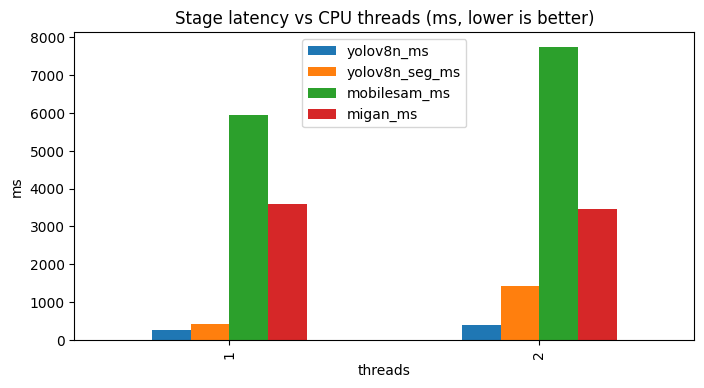

In [54]:
THREAD_OPTIONS = sorted({1, max(1, CPU_THREADS // 2), CPU_THREADS})
img = read_image("car_2.jpg")
bbox0 = max(detect_coco(img, "car"), key=lambda d: d["confidence"])["bbox"]
rm0 = build_removal_mask(segment_boxes(img, [bbox0])[0], [bbox0], img.shape)

thread_rows = []
for t in THREAD_OPTIONS:
    torch.set_num_threads(t)
    cv2.setNumThreads(t)
    sess = make_ort_session(MIGAN_PATH, threads=t)
    thread_rows.append({
        "threads": t,
        "yolov8n_ms": time_it(lambda: detect_coco(img, "car"), 5) * 1000,
        "yolov8n_seg_ms": time_it(lambda: detect_coco(img, "car", model=seg_model), 5) * 1000,
        "mobilesam_ms": time_it(lambda: segment_boxes(img, [bbox0]), 3) * 1000,
        "migan_ms": time_it(lambda: migan_inpaint(img, rm0, session=sess), 3) * 1000,
    })
    print(thread_rows[-1])

torch.set_num_threads(CPU_THREADS)
cv2.setNumThreads(CPU_THREADS)

threads_df = pd.DataFrame(thread_rows).set_index("threads")
threads_df.to_csv(os.path.join(BENCHMARK_DIR, "e6_thread_scaling.csv"))
threads_df.plot.bar(figsize=(8, 4), title="Stage latency vs CPU threads (ms, lower is better)")
plt.ylabel("ms")
plt.savefig(os.path.join(RESULTS_DIR, "e6_threads.png"), dpi=120, bbox_inches="tight")
plt.show()

## 6.2 Segmentation ablation: YOLOv8n + MobileSAM vs YOLOv8n-seg

YOLOv8n-seg returns the box **and** the mask in one forward pass. The questions:

* Is its coarser mask good enough once `removal_mask` has dilated it?
* How much latency and size does dropping MobileSAM save?

IoU is measured against the MobileSAM mask, which serves as the reference.

,image,class,mask_iou_vs_sam,yolo+mobilesam_ms,yolov8n_seg_ms
0,car_2.jpg,car,0.948,6210.742,447.921
1,car.jpg,car,0.934,7155.858,1438.381
2,park_2.jpg,person,0.903,8407.230,502.546
3,road_2.jpg,bicycle,0.823,10866.830,1002.899
4,cat.jpg,cat,0.915,7836.137,533.412


Size: YOLOv8n + MobileSAM = 45.1 MB | YOLOv8n-seg = 6.7 MB


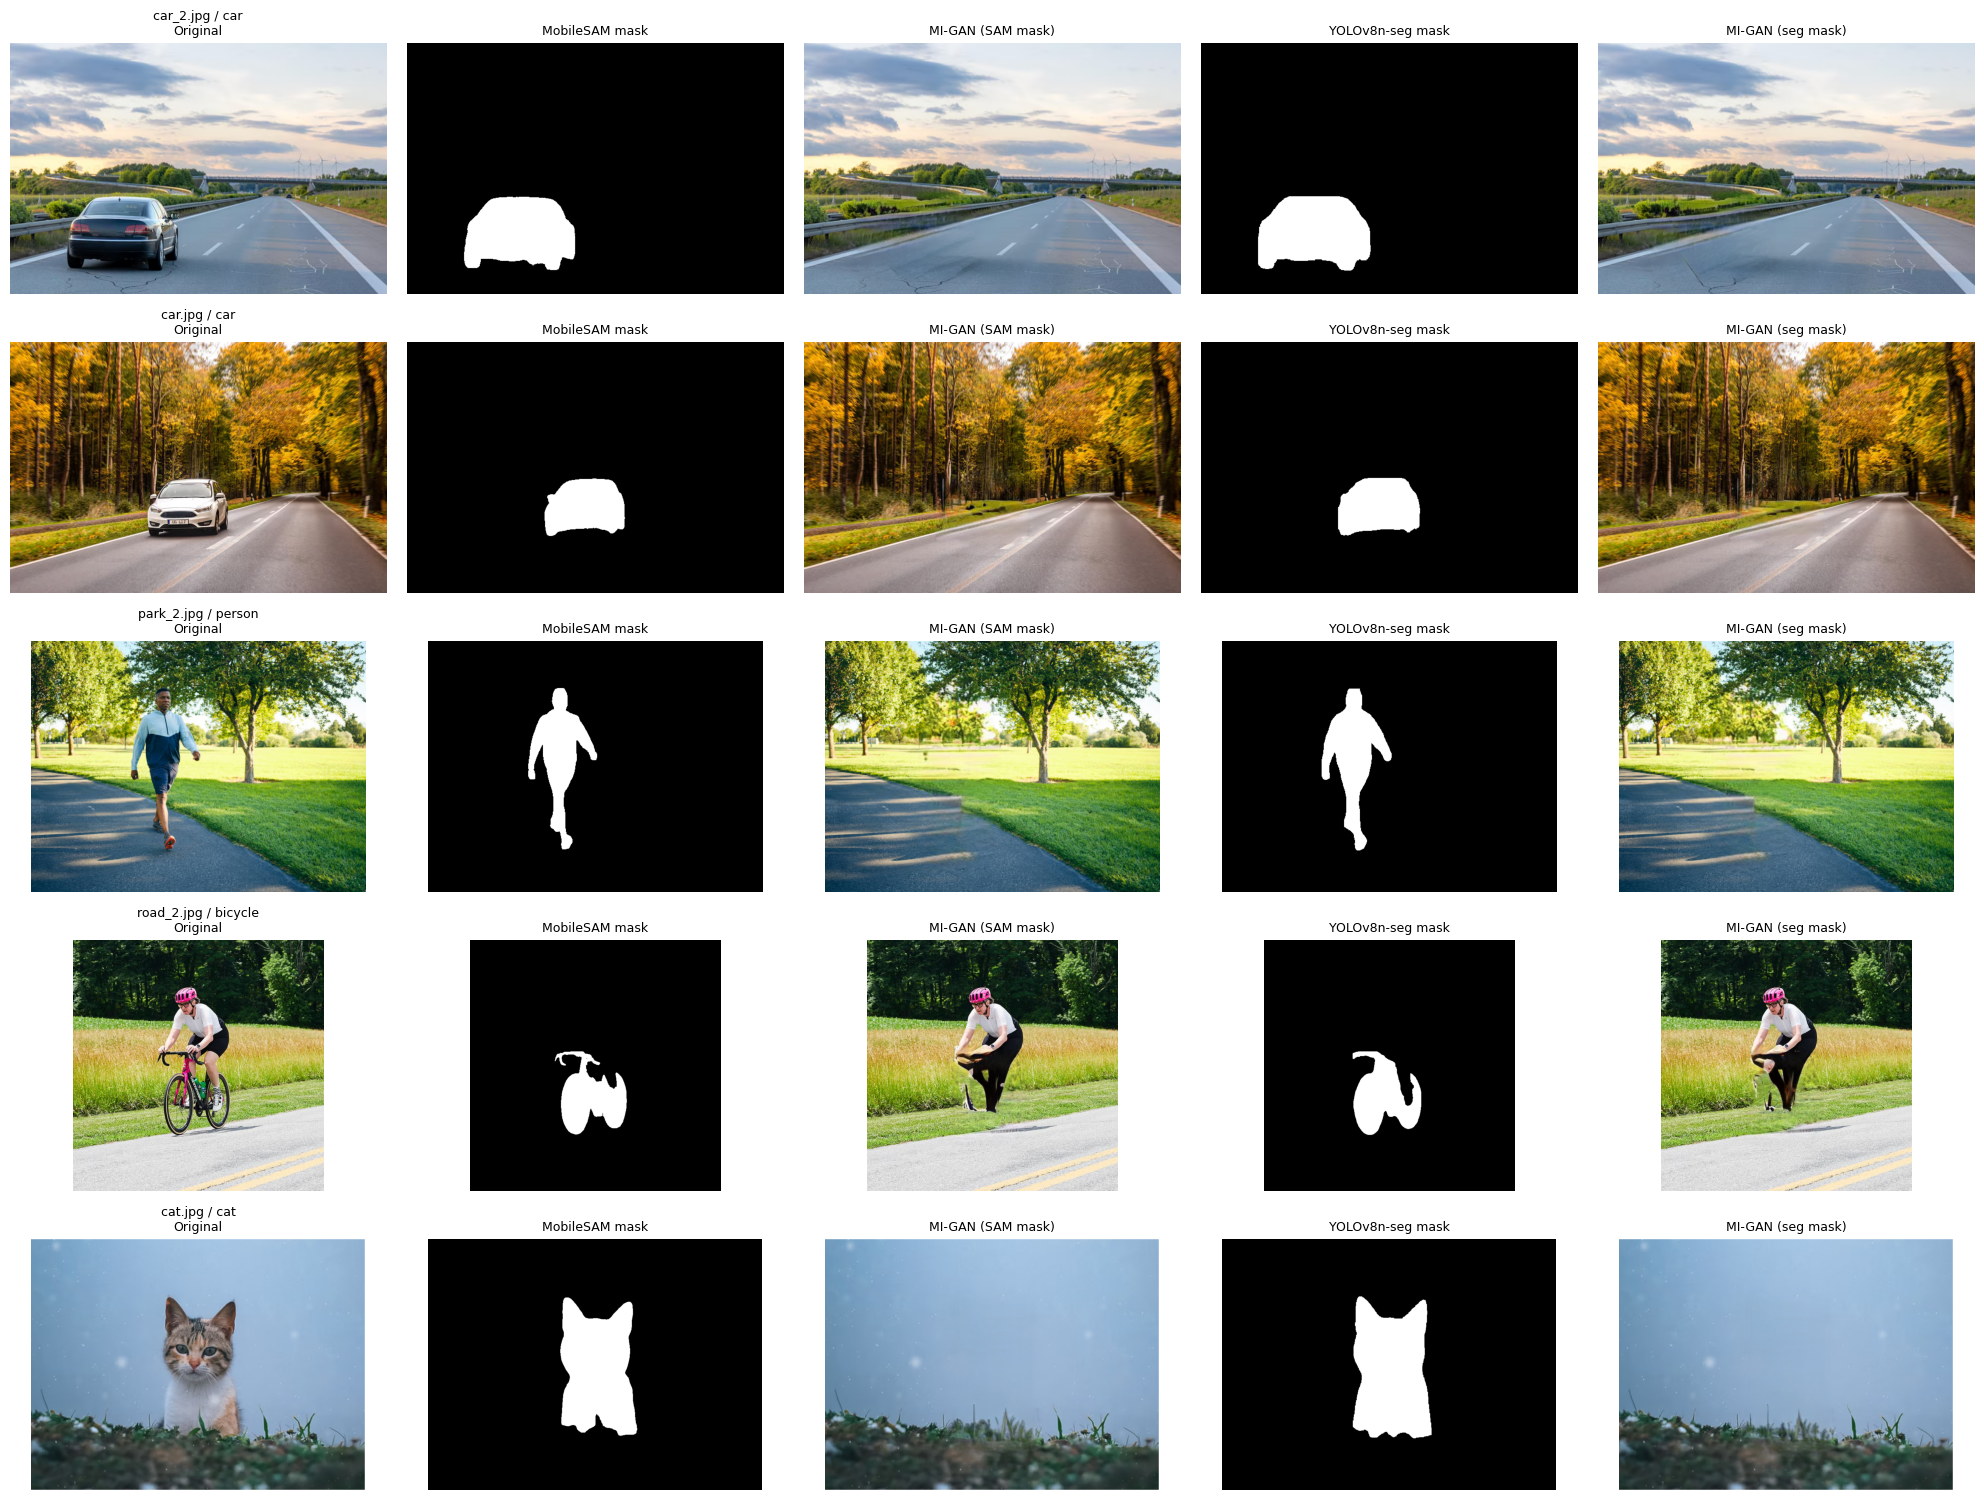

In [55]:
SEG_CASES = [("car_2.jpg", "car"), ("car.jpg", "car"), ("park_2.jpg", "person"), ("road_2.jpg", "bicycle"), ("cat.jpg", "cat")]

seg_rows, seg_vis = [], []
for img_name, cls in SEG_CASES:
    image = read_image(img_name)

    t0 = time.perf_counter()
    d = max(detect_coco(image, cls), key=lambda x: x["confidence"])
    sam_mask = segment_boxes(image, [d["bbox"]])[0][0]
    t_sam = time.perf_counter() - t0

    t0 = time.perf_counter()
    sd = max(detect_coco(image, cls, model=seg_model), key=lambda x: x["confidence"])
    seg_mask = polygon_to_mask(sd["polygon"], image.shape)
    t_seg = time.perf_counter() - t0

    out_sam, _ = migan_inpaint(image, build_removal_mask([sam_mask], [d["bbox"]], image.shape))
    out_seg, _ = migan_inpaint(image, build_removal_mask([seg_mask], [sd["bbox"]], image.shape))

    seg_rows.append({"image": img_name, "class": cls, "mask_iou_vs_sam": mask_iou(sam_mask, seg_mask),
                     "yolo+mobilesam_ms": t_sam * 1000, "yolov8n_seg_ms": t_seg * 1000})
    seg_vis.append([image, sam_mask, out_sam, seg_mask, out_seg])

seg_df = pd.DataFrame(seg_rows)
seg_df.to_csv(os.path.join(BENCHMARK_DIR, "e6_segmentation_ablation.csv"), index=False)
display(seg_df.round(3))
print(f"Size: YOLOv8n + MobileSAM = {YOLO_SIZE_MB + MOBILE_SAM_SIZE_MB:.1f} MB | YOLOv8n-seg = {SEG_SIZE_MB:.1f} MB")
show_grid(seg_vis, ["Original", "MobileSAM mask", "MI-GAN (SAM mask)", "YOLOv8n-seg mask", "MI-GAN (seg mask)"],
          row_titles=[f"{i} / {c}" for i, c in SEG_CASES], cell=4, save_as="e6_segmentation_ablation.jpg")

## 6.3 YOLOv8n-seg: PyTorch vs ONNX Runtime

In [56]:
SEG_RUNTIME, SEG_RUNTIME_NAME, SEG_RUNTIME_MB = seg_model, "yolov8n-seg (PyTorch)", SEG_SIZE_MB
try:
    onnx_path = seg_model.export(format="onnx", imgsz=640, simplify=True, dynamic=False)
    seg_onnx = YOLO(onnx_path, task="segment")
    img = read_image("car_2.jpg")
    t_pt = time_it(lambda: seg_model.predict(img, imgsz=640, device=DEVICE, verbose=False), 10)
    t_onnx = time_it(lambda: seg_onnx.predict(img, imgsz=640, device=DEVICE, verbose=False), 10)
    m_pt = polygon_to_mask(max(detect_coco(img, "car", model=seg_model), key=lambda d: d["confidence"])["polygon"], img.shape)
    m_onnx = polygon_to_mask(max(detect_coco(img, "car", model=seg_onnx), key=lambda d: d["confidence"])["polygon"], img.shape)
    onnx_df = pd.DataFrame([
        {"runtime": "PyTorch", "latency_ms": t_pt * 1000, "file_MB": SEG_SIZE_MB},
        {"runtime": "ONNX Runtime", "latency_ms": t_onnx * 1000, "file_MB": file_mb(onnx_path)},
    ])
    onnx_df.to_csv(os.path.join(BENCHMARK_DIR, "e6_onnx_export.csv"), index=False)
    display(onnx_df.round(2))
    print("Mask IoU PyTorch vs ONNX:", round(mask_iou(m_pt, m_onnx), 4))
    if t_onnx < t_pt:
        SEG_RUNTIME, SEG_RUNTIME_NAME, SEG_RUNTIME_MB = seg_onnx, "yolov8n-seg (ONNX Runtime)", file_mb(onnx_path)
except Exception as exc:
    print("ONNX export/inference failed -> keeping PyTorch:", exc)
print("Final pipeline uses:", SEG_RUNTIME_NAME)

Ultralytics 8.4.166 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLOv8n-seg summary (fused): 85 layers, 3,404,320 parameters, 0 gradients, 12.0 GFLOPs

PyTorch: starting from 'yolov8n-seg.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) ((1, 116, 8400), (1, 32, 160, 160)) (6.7 MB)

ONNX: starting export with onnx 1.23.1 opset 18...
ONNX: slimming with onnxslim 0.1.97...
ONNX: export success ✅ 8.8s, saved as 'yolov8n-seg.onnx' (13.2 MB)

Export complete (10.9s)
Results saved to /content/yolov8n-seg.onnx
Predict:         yolo predict task=segment model=yolov8n-seg.onnx imgsz=640 
Validate:        yolo val task=segment model=yolov8n-seg.onnx imgsz=640 data=coco.yaml  
Visualize:       https://netron.app
Loading yolov8n-seg.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.30.0 with CPUExecutionProvider


,runtime,latency_ms,file_MB
0,PyTorch,320.86,6.74
1,ONNX Runtime,444.33,13.23


Mask IoU PyTorch vs ONNX: 0.9986
Final pipeline uses: yolov8n-seg (PyTorch)


## 6.4 Diffusion knobs (replacement)

Everything here uses the same case (`car_2.jpg`, car → bicycle) and the same clean MI-GAN background. Only the diffusion stage is timed.

2 steps | 384px | taesd | cfg 1.0 -> 23.2s  p=0.98
4 steps | 384px | taesd | cfg 1.0 -> 38.8s  p=1.00
4 steps | 512px | taesd | cfg 1.0 -> 79.2s  p=0.99
6 steps | 512px | taesd | cfg 1.0 -> 103.7s  p=1.00
4 steps | 512px | full | cfg 1.0 -> 142.0s  p=1.00
4 steps | 512px | taesd | cfg 1.5 -> 131.7s  p=0.99


,config,steps,size,vae,guidance,diffusion_sec,clip_p_target,clip_p_source,clip_p_background
0,2 steps | 384px | taesd | cfg 1.0,2,384,taesd,1.0,23.206,0.984,0.006,0.010
1,4 steps | 384px | taesd | cfg 1.0,4,384,taesd,1.0,38.849,0.995,0.001,0.004
2,4 steps | 512px | taesd | cfg 1.0,4,512,taesd,1.0,79.213,0.994,0.001,0.005
3,6 steps | 512px | taesd | cfg 1.0,6,512,taesd,1.0,103.663,0.998,0.001,0.001
4,4 steps | 512px | full | cfg 1.0,4,512,full,1.0,142.047,0.997,0.002,0.001
5,4 steps | 512px | taesd | cfg 1.5,4,512,taesd,1.5,131.676,0.995,0.001,0.005


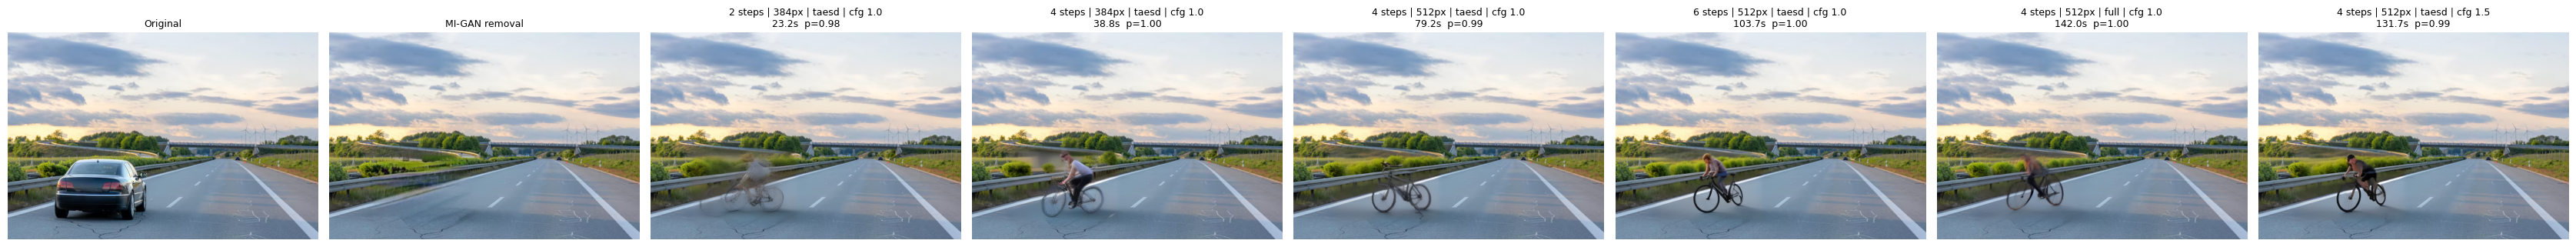

In [57]:
def prepare_clean(image, coco_class):
    d = max(detect_coco(image, coco_class), key=lambda x: x["confidence"])
    masks, _ = segment_boxes(image, [d["bbox"]])
    clean, _ = migan_inpaint(image, build_removal_mask(masks, [d["bbox"]], image.shape))
    return clean, d["bbox"]


SWEEP_IMAGE, SWEEP_SOURCE, SWEEP_TARGET = "car_2.jpg", "car", "bicycle"
SWEEP_CONFIGS = [
    {"steps": 2, "size": 384, "vae": "taesd", "guidance": 1.0},
    {"steps": 4, "size": 384, "vae": "taesd", "guidance": 1.0},
    {"steps": 4, "size": 512, "vae": "taesd", "guidance": 1.0},
    {"steps": 6, "size": 512, "vae": "taesd", "guidance": 1.0},
    {"steps": 4, "size": 512, "vae": "full", "guidance": 1.0},
    {"steps": 4, "size": 512, "vae": "taesd", "guidance": 1.5},
]

image = read_image(SWEEP_IMAGE)
clean, bbox = prepare_clean(image, SWEEP_SOURCE)
place = placement_mask(bbox, image.shape)
prompt = default_target_prompt(SWEEP_TARGET)

sweep_rows, sweep_imgs, sweep_titles = [], [image, clean], ["Original", "MI-GAN removal"]
for cfg in SWEEP_CONFIGS:
    if cfg["vae"] == "taesd" and not TAESD_OK:
        continue
    set_vae(cfg["vae"])
    out, dt = sd_generate_in_region(clean, place, bbox, prompt, f"{SWEEP_SOURCE}, " + NEGATIVE_PROMPT,
                                    steps=cfg["steps"], guidance=cfg["guidance"], size=cfg["size"])
    q = clip_scores(out, bbox, SWEEP_TARGET, SWEEP_SOURCE)
    name = f"{cfg['steps']} steps | {cfg['size']}px | {cfg['vae']} | cfg {cfg['guidance']}"
    sweep_rows.append({"config": name, **cfg, "diffusion_sec": dt, **q})
    sweep_imgs.append(out)
    sweep_titles.append(f"{name}\n{dt:.1f}s  p={q['clip_p_target']:.2f}")
    print(sweep_titles[-1].replace("\n", " -> "))

set_vae("taesd")
sweep_df = pd.DataFrame(sweep_rows)
sweep_df.to_csv(os.path.join(BENCHMARK_DIR, "e6_diffusion_sweep.csv"), index=False)
display(sweep_df.round(3))
show_grid([sweep_imgs], sweep_titles, cell=4.2, save_as="e6_diffusion_sweep.jpg")

## 6.5 Final pipeline

Look at the 6.2 and 6.4 results first, then edit `FINAL_CONFIG`. For example, set `"fast_segmenter": "mobilesam"` if the YOLOv8n-seg masks were too coarse, or change `diff_steps` / `diff_size`.

In [58]:
FINAL_CONFIG = {
    "parser": "llm" if LLM_OK else "regex",
    "fast_segmenter": "yolov8n-seg",   # "yolov8n-seg" or "mobilesam" (decide from 6.2)
    "open_vocab": USE_OPEN_VOCAB,
    "replace_mode": "diffusion",       # "diffusion" (any text target) or "composite" (asset library, fast)
    "diff_steps": 4,
    "diff_size": 512,
    "diff_guidance": 1.0,
    "diff_vae": "taesd",
    "mask_grow": 15,
    "shadow_ratio": 0.15,
}


def edit_image(image, instruction, config=FINAL_CONFIG):
    """Text-driven removal / replacement. Returns (output, removal_mask, parsed, meta)."""
    times = {}

    t0 = time.perf_counter()
    parsed = smart_parse(instruction) if config["parser"] == "llm" else regex_parse(instruction)
    times["parse"] = time.perf_counter() - t0

    # ---- grounding router ----
    t0 = time.perf_counter()
    chosen, route = [], "none"
    if parsed["coco_class"] in COCO_NAMES:
        model = SEG_RUNTIME if config["fast_segmenter"] == "yolov8n-seg" else yolo_model
        chosen = select_detections(detect_coco(image, parsed["coco_class"], model=model), parsed["which"], image.shape)
        route = f"coco -> {config['fast_segmenter']}"
    if not chosen and config["open_vocab"]:
        dets, _ = detect_open_vocab(image, parsed["object"] or parsed["coco_class"], "world")
        chosen = select_detections(dets, parsed["which"], image.shape)
        route = "open-vocab -> YOLO-World + MobileSAM"
    times["detect"] = time.perf_counter() - t0
    if not chosen:
        raise ValueError(f"Could not find {parsed['object']!r} in the image")
    boxes = [d["bbox"] for d in chosen]

    # ---- masks ----
    t0 = time.perf_counter()
    if all("polygon" in d for d in chosen):
        masks = [polygon_to_mask(d["polygon"], image.shape) for d in chosen]
    else:
        masks, _ = segment_boxes(image, boxes)
    times["segment"] = time.perf_counter() - t0

    # ---- removal ----
    rm = build_removal_mask(masks, boxes, image.shape, config["mask_grow"], config["shadow_ratio"])
    clean, times["remove"] = migan_inpaint(image, rm)
    output, insert_mode = clean, ""

    # ---- replacement ----
    times["insert"] = 0.0
    if parsed["action"] == "replace":
        bbox = boxes[0]
        asset = find_asset(parsed["target"]) if config["replace_mode"] == "composite" else None
        t0 = time.perf_counter()
        if asset:
            output = composite_object(clean, load_asset_rgba(asset), bbox)
            insert_mode = "composite"
        else:
            set_vae(config["diff_vae"])
            output, _ = sd_generate_in_region(
                clean, placement_mask(bbox, image.shape), bbox, parsed["target_prompt"],
                negative_prompt=f"{parsed['object']}, " + NEGATIVE_PROMPT,
                steps=config["diff_steps"], guidance=config["diff_guidance"], size=config["diff_size"],
            )
            insert_mode = "lcm-sd"
        times["insert"] = time.perf_counter() - t0

    times["total"] = sum(times.values())
    meta = {"route": route, "insert_mode": insert_mode, "n_selected": len(chosen),
            **{f"{k}_sec": v for k, v in times.items()}}
    return output, rm, parsed, meta


FINAL_CASES = [
    ("car_2.jpg", "Could you get rid of the dark sedan on the highway?"),
    ("park.jpg", "remove the woman on the left"),
    ("park_2.jpg", "I don't want the man walking in this photo"),
    ("multi.jpg", "remove the hat"),
    ("multi.jpg", "delete the ladder"),
    ("car_2.jpg", "swap the car for a red bicycle"),
    ("cat.jpg", "turn the kitten into a golden retriever puppy"),
    ("park_2.jpg", "replace the man with a dog"),
]

## 6.6 Final benchmark (per-stage latency + peak RAM)

,MB
parser (LLM),468.6
yolov8n-seg (PyTorch),6.7
YOLO-World-S + text encoder (open vocab),24.7
MobileSAM (open-vocab path),38.8
MI-GAN (ONNX),26.8
SD-1.5 inpaint UNet (LCM fused) + text encoder,3748.3
VAE (TAESD or full),9.3


Removal-only deployment: 566 MB | Removal + replacement: 4323 MB
car_2.jpg | Could you get rid of the dark sedan on the highway? | coco -> yolov8n-seg | 11.44s | peak RSS 8770 MB
park.jpg | remove the woman on the left | coco -> yolov8n-seg | 6.24s | peak RSS 8771 MB
park_2.jpg | I don't want the man walking in this photo | coco -> yolov8n-seg | 11.42s | peak RSS 8776 MB
multi.jpg | remove the hat | FAILED: Could not find 'hat' in the image
multi.jpg | delete the ladder | open-vocab -> YOLO-World + MobileSAM | 12.77s | peak RSS 9416 MB
car_2.jpg | swap the car for a red bicycle | coco -> yolov8n-seg | 85.73s | peak RSS 9497 MB
cat.jpg | turn the kitten into a golden retriever puppy | open-vocab -> YOLO-World + MobileSAM | 91.47s | peak RSS 9487 MB
park_2.jpg | replace the man with a dog | open-vocab -> YOLO-World + MobileSAM | 86.46s | peak RSS 9467 MB


,parse_sec,detect_sec,segment_sec,remove_sec,insert_sec,total_sec,peak_rss_MB
action,,,,,,,
remove,7.57,0.43,0.87,1.60,0.00,10.47,8933.16
replace,9.39,0.95,2.36,2.36,72.82,87.89,9483.58


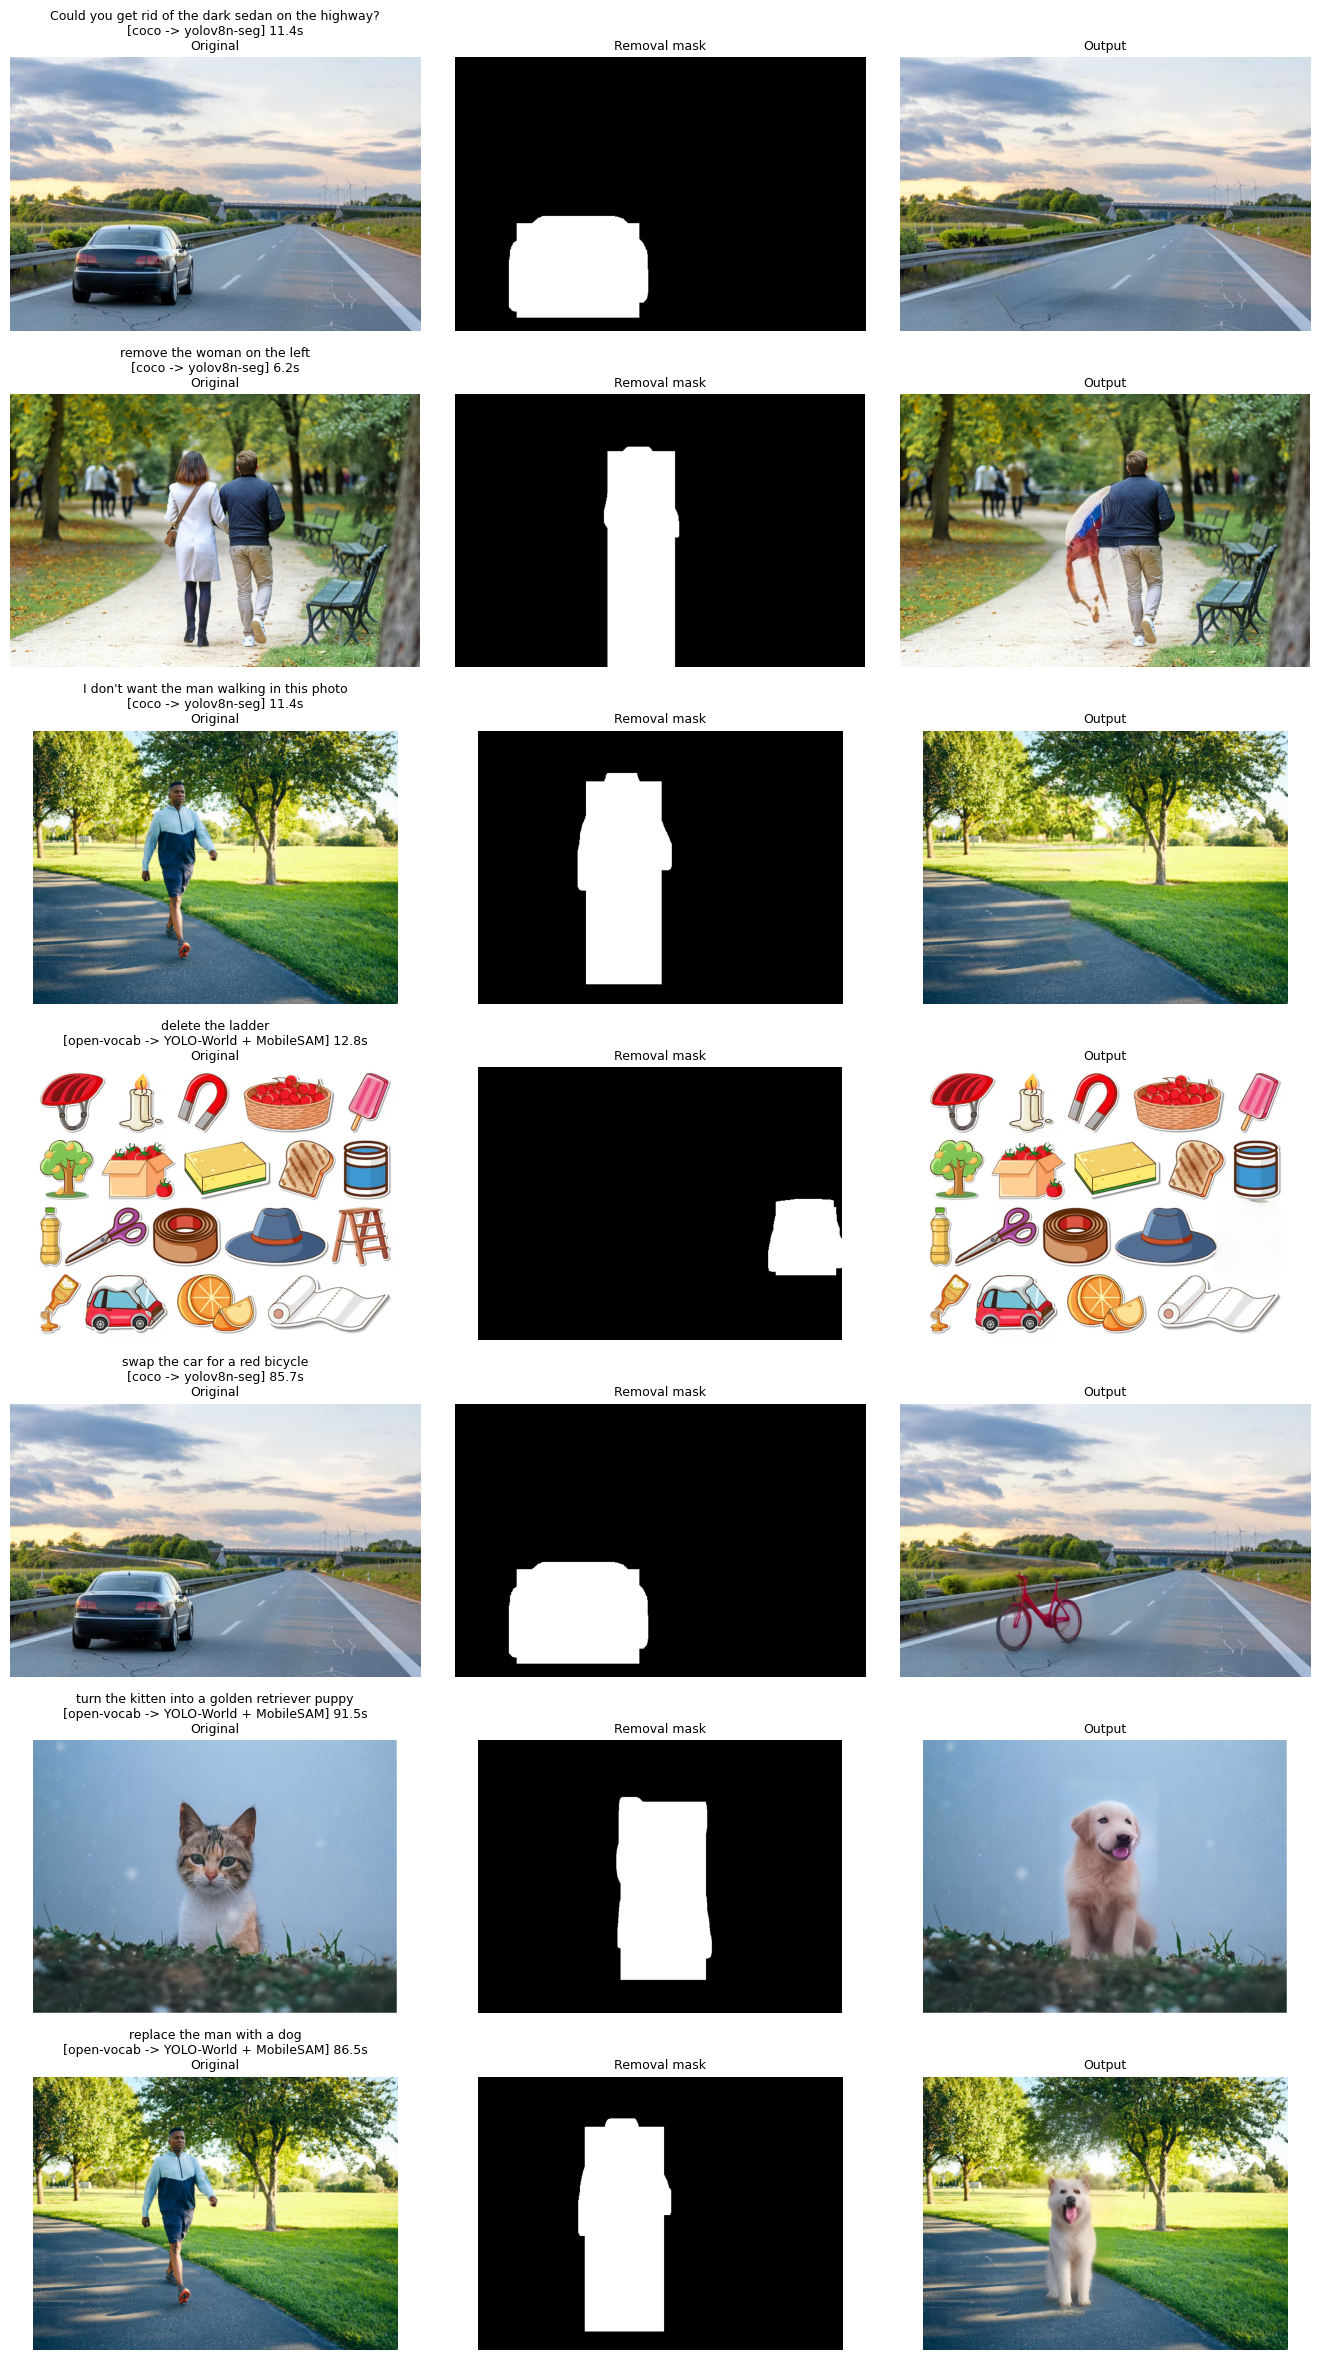

In [59]:
FINAL_SIZES = {
    "parser (LLM)": LLM_SIZE_MB if FINAL_CONFIG["parser"] == "llm" else 0.0,
    SEG_RUNTIME_NAME: SEG_RUNTIME_MB if FINAL_CONFIG["fast_segmenter"] == "yolov8n-seg" else YOLO_SIZE_MB,
    "YOLO-World-S + text encoder (open vocab)": (WORLD_SIZE_MB + WORLD_TEXT_MB) if USE_OPEN_VOCAB else 0.0,
    "MobileSAM (open-vocab path)": MOBILE_SAM_SIZE_MB if (USE_OPEN_VOCAB or FINAL_CONFIG["fast_segmenter"] == "mobilesam") else 0.0,
    "MI-GAN (ONNX)": MIGAN_SIZE_MB,
    "SD-1.5 inpaint UNet (LCM fused) + text encoder": SD_PARTS_MB["unet"] + SD_PARTS_MB["text_encoder"],
    "VAE (TAESD or full)": TAESD_MB if (TAESD_OK and FINAL_CONFIG["diff_vae"] == "taesd") else SD_PARTS_MB["vae"],
}
sizes_df = pd.Series(FINAL_SIZES, name="MB").round(1)
REMOVAL_ONLY_MB = sum(v for k, v in FINAL_SIZES.items() if not k.startswith(("SD-1.5", "VAE")))
FULL_MB = sum(FINAL_SIZES.values())
display(sizes_df)
print(f"Removal-only deployment: {REMOVAL_ONLY_MB:.0f} MB | Removal + replacement: {FULL_MB:.0f} MB")

edit_image(read_image(FINAL_CASES[0][0]), FINAL_CASES[0][1])   # warm-up

final_rows, final_vis, final_titles = [], [], []
for img_name, instruction in FINAL_CASES:
    image = read_image(img_name)
    try:
        with PeakRSS() as mem:
            out, rm, parsed, meta = edit_image(image, instruction)
    except Exception as exc:
        print(f"{img_name} | {instruction} | FAILED: {exc}")
        final_rows.append({"image": img_name, "instruction": instruction, "error": str(exc)[:120]})
        continue
    row = {"variant": f"E6-final-{parsed['action']}", "image": img_name, "instruction": instruction,
           "action": parsed["action"], "object": parsed["object"], "which": parsed["which"],
           "target": parsed["target"], "parser": parsed["parser"], **meta,
           "peak_rss_MB": mem.peak_mb, "peak_rss_delta_MB": mem.delta_mb,
           "model_size_MB": FULL_MB if parsed["action"] == "replace" else REMOVAL_ONLY_MB, "error": ""}
    if parsed["action"] == "replace":
        bbox = [float(v) for v in cv2.boundingRect(rm)]
        bbox = [bbox[0], bbox[1], bbox[0] + bbox[2], bbox[1] + bbox[3]]
        row.update(clip_scores(out, bbox, parsed["target"], parsed["object"]))
    final_rows.append(row)
    save_image(out, f"final_{Path(img_name).stem}_{slug(instruction)}.jpg")
    final_vis.append([image, rm, out])
    final_titles.append(f"{instruction}\n[{meta['route']}] {meta['total_sec']:.1f}s")
    print(f"{img_name} | {instruction} | {meta['route']} | {meta['total_sec']:.2f}s | peak RSS {mem.peak_mb:.0f} MB")

final_df = pd.DataFrame(final_rows)
final_df.to_csv(os.path.join(BENCHMARK_DIR, "e6_final_benchmark.csv"), index=False)
stage = [c for c in ["parse_sec", "detect_sec", "segment_sec", "remove_sec", "insert_sec", "total_sec", "peak_rss_MB"] if c in final_df]
display(final_df.groupby("action")[stage].mean().round(2))
show_grid(final_vis, ["Original", "Removal mask", "Output"], row_titles=final_titles, cell=4.5,
          save_as="e6_final_results.jpg")

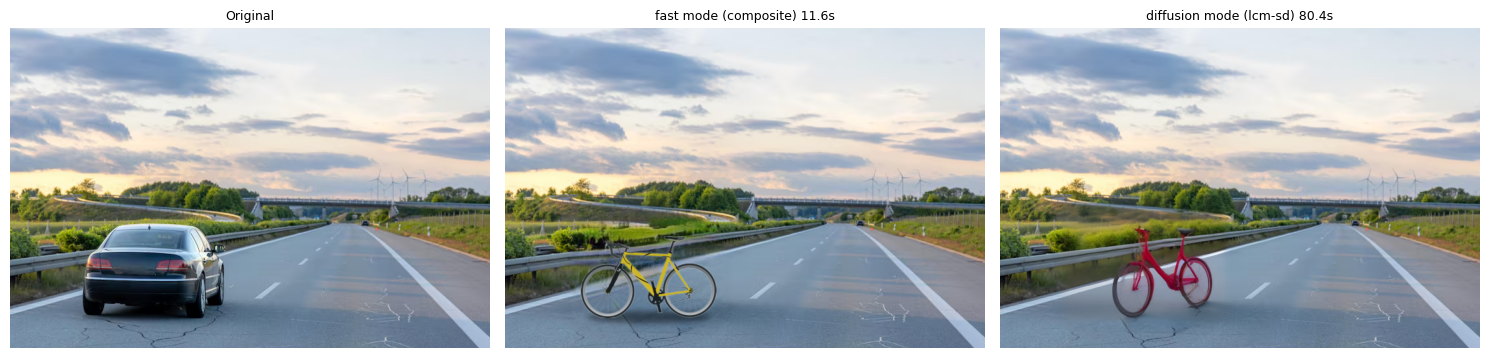

In [60]:
# Fast mode: composite from the asset library instead of diffusion (same instruction, same image)
fast_cfg = dict(FINAL_CONFIG, replace_mode="composite")
image = read_image("car_2.jpg")
fast_out, _, _, fast_meta = edit_image(image, "swap the car for a red bicycle", config=fast_cfg)
diff_out, _, _, diff_meta = edit_image(image, "swap the car for a red bicycle")
show_grid([[image, fast_out, diff_out]],
          ["Original", f"fast mode ({fast_meta['insert_mode']}) {fast_meta['total_sec']:.1f}s",
           f"diffusion mode ({diff_meta['insert_mode']}) {diff_meta['total_sec']:.1f}s"],
          cell=5, save_as="e6_fast_vs_diffusion.jpg")

## 6.7 Runtime dependency footprint

This is the installed size of each Python package the pipeline imports. On an edge device the dependencies can outweigh the model files, and `torch` is the largest of them.

In [61]:
from importlib import metadata


def dist_size_mb(name):
    try:
        dist = metadata.distribution(name)
    except metadata.PackageNotFoundError:
        return None
    total = 0
    for f in dist.files or []:
        try:
            total += os.path.getsize(dist.locate_file(f))
        except OSError:
            pass
    return total / 2**20


PACKAGES = {
    "torch": "core", "torchvision": "core", "numpy": "core", "pillow": "core",
    "opencv-python": "core", "opencv-python-headless": "core", "opencv-contrib-python": "core",
    "onnxruntime": "core", "ultralytics": "detection", "mobile-sam": "segmentation", "timm": "segmentation",
    "clip": "open-vocab", "llama-cpp-python": "parser", "transformers": "parser/diffusion",
    "tokenizers": "parser/diffusion", "diffusers": "diffusion", "accelerate": "diffusion",
    "safetensors": "diffusion", "huggingface-hub": "diffusion", "peft": "diffusion (LoRA load only)",
}
dep_df = pd.DataFrame([{"package": p, "role": r, "installed_MB": dist_size_mb(p)} for p, r in PACKAGES.items()])
dep_df = dep_df.dropna().sort_values("installed_MB", ascending=False)
dep_df.to_csv(os.path.join(BENCHMARK_DIR, "e6_dependency_footprint.csv"), index=False)
display(dep_df.round(1))

ort_only = dep_df[dep_df.package.isin(["onnxruntime", "numpy", "opencv-python", "opencv-python-headless"])].installed_MB.sum()
print(f"All pipeline dependencies: {dep_df.installed_MB.sum():.0f} MB")
print(f"ONNX-Runtime-only removal path (YOLOv8n-seg ONNX + MI-GAN ONNX, needs a numpy post-processor): ~{ort_only:.0f} MB")

,package,role,installed_MB
0,torch,core,669.2
6,opencv-contrib-python,core,214.1
4,opencv-python,core,196.4
5,opencv-python-headless,core,161.8
12,llama-cpp-python,parser,66.9
7,onnxruntime,core,64.8
2,numpy,core,52.4
13,transformers,parser/diffusion,47.1
15,diffusers,diffusion,24.8
3,pillow,core,16.7


All pipeline dependencies: 1565 MB
ONNX-Runtime-only removal path (YOLOv8n-seg ONNX + MI-GAN ONNX, needs a numpy post-processor): ~475 MB


## 6.8 Consolidated summary: E0 → E6

The numbers come from the CSVs each notebook saved. Rows marked `log` come from notebook output logs because no CSV exists, so check them.

**Edit `QUALITY_NOTES` after looking at the result grids.**

In [62]:
def load_latency(path, where=None):
    """Mean end-to-end latency (s) from a benchmark CSV, whatever its column naming."""
    if not os.path.exists(path):
        return None
    df = pd.read_csv(path)
    if where:
        for col, val in where.items():
            if col in df:
                df = df[df[col] == val]
    if "error" in df:
        df = df[df["error"].fillna("") == ""]
    for col, scale in [("total_sec", 1), ("mean_latency_sec", 1), ("total_time_sec", 1),
                       ("end_to_end_latency_ms", 1e-3), ("mean_latency_ms", 1e-3)]:
        if col in df and len(df):
            return float(df[col].mean() * scale)
    return None


B = BENCHMARK_DIR
SD_FULL_MB = sum(SD_PARTS_MB.values())
LAMA_PATH = os.path.join(MODEL_DIR, "big-lama.pt")
LAMA_MB = file_mb(LAMA_PATH) if os.path.exists(LAMA_PATH) else 196.0
E1_MB = YOLO_SIZE_MB + MOBILE_SAM_SIZE_MB

summary_rows = [
    ("E0 box + Telea", "remove", load_latency(f"{B}/e0_benchmark.csv", {"operation": "remove"}), YOLO_SIZE_MB, "csv"),
    ("E0 box + paste", "replace", load_latency(f"{B}/e0_benchmark.csv", {"operation": "replace"}), YOLO_SIZE_MB, "csv"),
    ("E1 MobileSAM + Telea", "remove", load_latency(f"{B}/e1_benchmark.csv", {"operation": "remove"}), E1_MB, "csv"),
    ("E1 MobileSAM + paste", "replace", load_latency(f"{B}/e1_benchmark.csv", {"operation": "replace"}), E1_MB, "csv"),
    ("E2-A SD-inpaint only", "remove", load_latency(f"{B}/e2a_benchmark.csv", {"action": "remove"}) or 116.9, E1_MB + SD_FULL_MB, "log"),
    ("E2-A SD-inpaint only", "replace", load_latency(f"{B}/e2a_benchmark.csv", {"action": "replace"}) or 104.8, E1_MB + SD_FULL_MB, "log"),
    ("E3 MI-GAN", "remove", load_latency(f"{B}/e3_migan_benchmark.csv"), E1_MB + MIGAN_SIZE_MB, "csv"),
    ("E3 LaMa", "remove", load_latency(f"{B}/e3_lama_benchmark.csv"), E1_MB + LAMA_MB, "csv"),
]

for fname in ["e4_benchmark.csv", "e5_replace_benchmark.csv", "e6_final_benchmark.csv"]:
    path = os.path.join(B, fname)
    if os.path.exists(path):
        df = pd.read_csv(path)
        df = df[df["error"].fillna("") == ""] if "error" in df else df
        for variant, g in df.groupby("variant"):
            task = "replace" if ("E5" in variant or "replace" in variant) else "remove"
            summary_rows.append((variant, task, float(g["total_sec"].mean()), float(g["model_size_MB"].iloc[0]), "csv"))

summary = pd.DataFrame(summary_rows, columns=["pipeline", "task", "latency_sec", "model_size_MB", "source"])
summary = summary.dropna(subset=["latency_sec"])

QUALITY_NOTES = {   # <- edit after looking at the grids
    "E0 box + Telea": "poor: blurry box-shaped smear",
    "E1 MobileSAM + Telea": "poor: object-shaped smear",
    "E2-A SD-inpaint only": "unreliable: regenerates the removed object",
    "E3 MI-GAN": "good on roads/grass; struggles with large masks",
    "E3 LaMa": "best removal texture; larger and slower",
}
summary["quality"] = summary["pipeline"].map(QUALITY_NOTES).fillna("see result grids")
summary.to_csv(os.path.join(BENCHMARK_DIR, "e6_summary_all_experiments.csv"), index=False)
display(summary.round(2))

,pipeline,task,latency_sec,model_size_MB,source,quality
0,E0 box + Telea,remove,0.32,6.25,csv,poor: blurry box-shaped smear
1,E0 box + paste,replace,0.38,6.25,csv,see result grids
2,E1 MobileSAM + Telea,remove,4.43,45.09,csv,poor: object-shaped smear
3,E1 MobileSAM + paste,replace,4.41,45.09,csv,see result grids
4,E2-A SD-inpaint only,remove,400.37,4112.51,log,unreliable: regenerates the removed object
5,E2-A SD-inpaint only,replace,419.20,4112.51,log,unreliable: regenerates the removed object
6,E3 MI-GAN,remove,3.44,71.87,csv,good on roads/grass; struggles with large masks
7,E3 LaMa,remove,12.21,241.36,csv,best removal texture; larger and slower
8,E4-A: regex + YOLOv8n,remove,6.15,71.87,csv,see result grids
9,E4-C: LLM + YOLO-World,remove,14.99,896.56,csv,see result grids


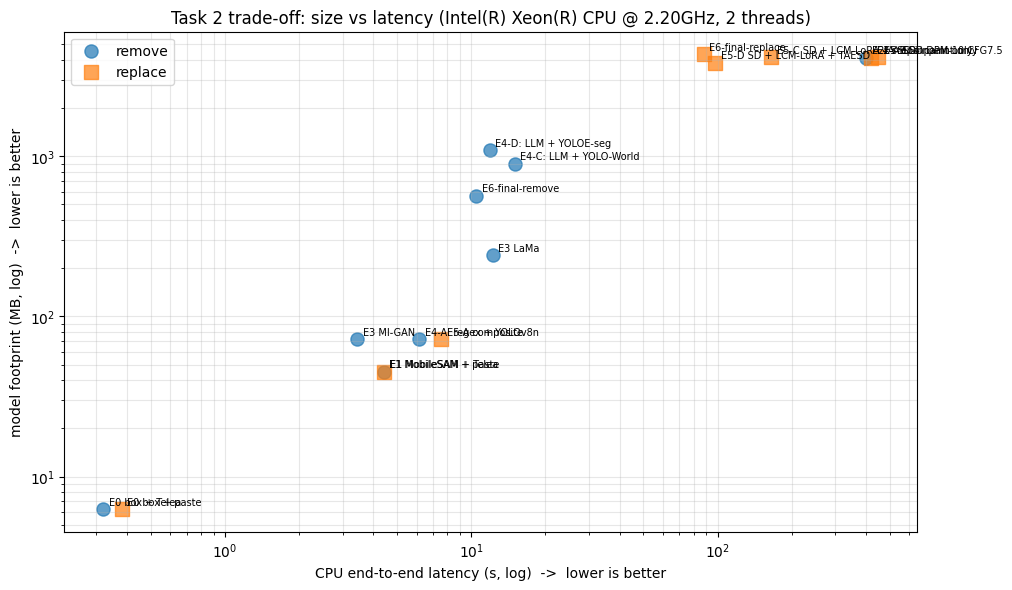

In [63]:
fig, ax = plt.subplots(figsize=(11, 6.5))
for task, marker in [("remove", "o"), ("replace", "s")]:
    s = summary[summary.task == task]
    ax.scatter(s["latency_sec"], s["model_size_MB"], marker=marker, s=90, alpha=0.7, label=task)
    for _, r in s.iterrows():
        ax.annotate(r["pipeline"], (r["latency_sec"], r["model_size_MB"]), fontsize=7,
                    xytext=(4, 3), textcoords="offset points")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("CPU end-to-end latency (s, log)  ->  lower is better")
ax.set_ylabel("model footprint (MB, log)  ->  lower is better")
ax.set_title(f"Task 2 trade-off: size vs latency ({SYSTEM_INFO['cpu']}, {CPU_THREADS} threads)")
ax.grid(alpha=0.3, which="both")
ax.legend()
plt.savefig(os.path.join(RESULTS_DIR, "e6_tradeoff_all_experiments.png"), dpi=130, bbox_inches="tight")
plt.show()

## 6.9 (Optional) int8 dynamic quantisation of the UNet

This converts the UNet's `nn.Linear` layers (attention and feed-forward) to int8, with activations quantised on the fly. The conv layers stay fp32.

**It runs last because it modifies the pipeline in place.** Re-run the notebook if you want fp32 results again.

/tmp/ipykernel_19267/1377488558.py:17: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  quantize_dynamic(pipe.unet, {torch.nn.Linear}, dtype=torch.qint8, inplace=True)


,unet,diffusion_sec,unet_MB,clip_p_target,clip_p_source,clip_p_background
0,fp32,71.507,3278.867,0.994,0.001,0.005
1,torch.ao dynamic int8 (Linear),67.711,2506.661,0.981,0.002,0.017


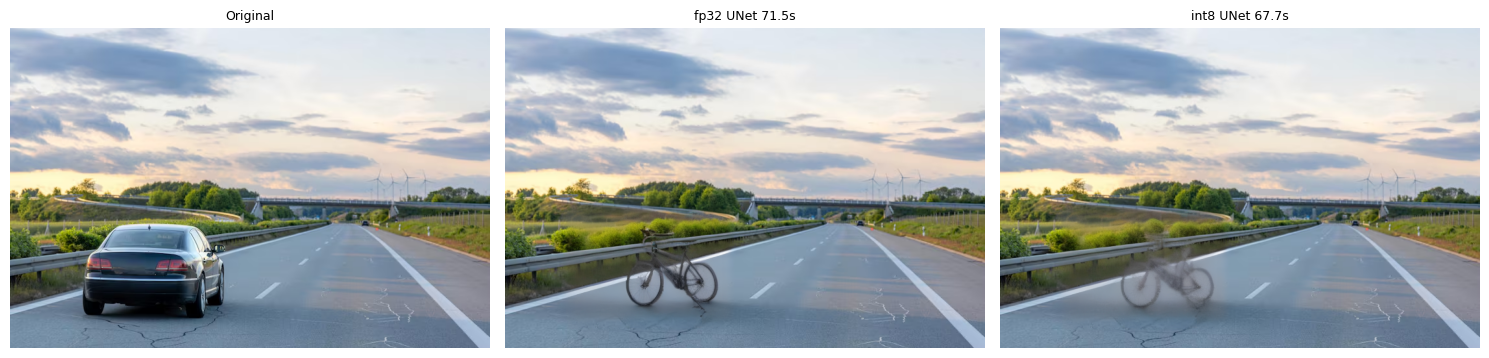

In [64]:
RUN_INT8_UNET = True

if RUN_INT8_UNET:
    try:
        set_vae("taesd")
        image = read_image(SWEEP_IMAGE)
        clean, bbox = prepare_clean(image, SWEEP_SOURCE)
        place = placement_mask(bbox, image.shape)
        prompt = default_target_prompt(SWEEP_TARGET)
        args = dict(steps=4, guidance=1.0, size=512)

        fp32_out, fp32_t = sd_generate_in_region(clean, place, bbox, prompt, **args)
        fp32_q = clip_scores(fp32_out, bbox, SWEEP_TARGET, SWEEP_SOURCE)

        try:
            from torch.ao.quantization import quantize_dynamic
            quantize_dynamic(pipe.unet, {torch.nn.Linear}, dtype=torch.qint8, inplace=True)
            method = "torch.ao dynamic int8 (Linear)"
        except ImportError:
            from torchao.quantization import quantize_, Int8DynamicActivationInt8WeightConfig  # pip install torchao
            quantize_(pipe.unet, Int8DynamicActivationInt8WeightConfig())
            method = "torchao int8 dynamic"

        sd_warmup()
        int8_out, int8_t = sd_generate_in_region(clean, place, bbox, prompt, **args)
        int8_q = clip_scores(int8_out, bbox, SWEEP_TARGET, SWEEP_SOURCE)

        tmp = "/content/unet_int8.pt"
        torch.save(pipe.unet.state_dict(), tmp)
        int8_mb = file_mb(tmp)

        int8_df = pd.DataFrame([
            {"unet": "fp32", "diffusion_sec": fp32_t, "unet_MB": SD_PARTS_MB["unet"], **fp32_q},
            {"unet": method, "diffusion_sec": int8_t, "unet_MB": int8_mb, **int8_q},
        ])
        int8_df.to_csv(os.path.join(BENCHMARK_DIR, "e6_int8_unet.csv"), index=False)
        display(int8_df.round(3))
        show_grid([[image, fp32_out, int8_out]],
                  ["Original", f"fp32 UNet {fp32_t:.1f}s", f"int8 UNet {int8_t:.1f}s"], cell=5,
                  save_as="e6_int8_unet.jpg")
    except Exception as exc:
        print("int8 quantisation not available / failed:", exc)

## Final observations (fill in; these go straight into the PPT)

* **Threads:** all __ cores vs 1 core gives a __× speed-up. MobileSAM and MI-GAN scale best / worst.
* **Segmentation:** YOLOv8n-seg vs MobileSAM gives IoU __, saves __ s and __ MB, and the removal quality is (same / worse).
* **ONNX:** YOLOv8n-seg runs __ ms on ONNX Runtime vs __ ms on PyTorch.
* **Diffusion:** the chosen setting is __ steps at __ px with TAESD, for __ s and p(target) __. Going from 384 to 512 px costs …
* **Final pipeline:**
  * Removal: __ s, __ MB, peak RAM __ MB.
  * Replacement: __ s, __ MB, peak RAM __ MB.
* **Dependencies:** __ MB in total, and torch accounts for __ %. A path that runs only on ONNX Runtime would need __ MB.
* **Bottlenecks:** the UNet (__ % of replacement time), and the LLM when using the transformers fallback.
* **Failure cases:** …
* **Future work:** export MobileSAM and the UNet to ONNX or OpenVINO, write a numpy YOLO post-processor to drop torch, and try SD-Turbo or a distilled UNet (BK-SDM).